# Metal demand against allocated supply

Three cubes, read side by side — they share a `metal` dimension, so lining them
up is the figure's job and no rule combines them:

- `build/metal_demand/metal_demand.nc` (`calculate_metal_demand`) — cumulative
  demand from the modelled energy transition over the study window, kt, over
  `(scenario, metal, technology)`. Already a quantity of *this* region.
- `build/non_energy_demand/non_energy_demand.nc`
  (`build_non_energy_demand`) — the region's own demand from every other sector
  over the same window, kt, over `(metal,)`.
- `build/allocation/final_supply_scaled.nc` (`allocate_supply`) — the same
  window's world supply, after the share of it this region may claim.

The three allocation principles come from Malmaeus et al. (2025) Table 3,
rescaled from the EU-27 to the modelled country set by
`compute_allocation_factors`. They are alternative answers to *how much of the
world's metal is ours*, not a range around one answer, so all three are drawn
and none is preferred.

They apply to supply alone. Other-sector demand is measured rather than
allocated: `rules/ned.smk` reads each metal's regional consumption off its
Material System Analysis chapter and carries that level forward on regional GDP.
There is therefore one other-sector band, not three, and the comparison reads:
*if the region were granted a fair share of world supply, would it cover what it
actually uses?*

Figures are ordered strictest principle first, which is the order of the shares
rather than the order the config declares them, and each principle is drawn
fainter than the one before: the innermost band and the lowest line are the
binding case.

Metals held out of the comparison are listed in `compare.excluded_metals` in
`config/default.yaml`; every metal that is not held out has to appear in all
three cubes, or the next cell stops. How the figures look is entirely in the
`plotting` and `compare` blocks of the config, applied by `scripts/plotting.py`.

Run by the `visualise_supply_and_demand` snakemake rule, or interactively (paths
then resolve relative to the repo root).

In [1]:
import sys
from pathlib import Path

import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml

# Snakemake runs this from the repo root, an interactive session from
# notebooks/; neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting
from utils import get_mineral_groups
from info_schemas import (
    SCENARIO_SEPARATOR,
    MAX_REDUCTION_SCENARIO,
    ScenarioEffect,
    ScenarioSummary,
    MaxReduction,
    MetalPosition,
    MineralInfo,
)

try:
    paths = {
        "demand": snakemake.input.demand,  # type: ignore
        "non_energy_demand": snakemake.input.non_energy_demand,  # type: ignore
        "supply": snakemake.input.supply,  # type: ignore
        "mineral_info": snakemake.input.mineral_info,  # type: ignore
        "positions": snakemake.input.positions,  # type: ignore
        "scenario_effects": snakemake.input.scenario_effects,  # type: ignore
        "scenario_summary": snakemake.input.scenario_summary,  # type: ignore
        "max_reduction": snakemake.input.max_reduction,  # type: ignore
        "max_reduction_demand": snakemake.input.max_reduction_demand,  # type: ignore
        "figures": snakemake.output.figures,  # type: ignore
    }
    technology_info = dict(snakemake.params.technology_info)  # type: ignore
    scenario_info = dict(snakemake.params.scenario_info)  # type: ignore
    scenario_groups = dict(snakemake.params.scenario_groups)  # type: ignore
    mineral_groups = dict(snakemake.params.mineral_groups)  # type: ignore
    base_scenario = snakemake.params.base_scenario  # type: ignore
    reference_method = snakemake.params.reference_method  # type: ignore
    allocation_style = dict(snakemake.params.allocation_style)  # type: ignore
    non_energy_style = dict(snakemake.params.non_energy_style)  # type: ignore
    share_axis = dict(snakemake.params.share_axis)  # type: ignore
    metal_types = dict(snakemake.params.metal_types)  # type: ignore
    metal_type_classes = dict(snakemake.params.metal_type_classes)  # type: ignore
    positions_style = dict(snakemake.params.positions_style)  # type: ignore
    floor_style = dict(snakemake.params.floor_style)  # type: ignore
    scenario_effects_style = dict(snakemake.params.scenario_effects_style)  # type: ignore
    max_reduction_style = dict(snakemake.params.max_reduction_style)  # type: ignore
    excluded_metals = list(snakemake.params.excluded_metals)  # type: ignore
    style = dict(snakemake.params.plotting)  # type: ignore
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        config = yaml.safe_load(f)
    technology_info = config["technology_info"]
    scenario_info = config["scenarios"]
    scenario_groups = config["scenario_groups"]
    mineral_groups = get_mineral_groups(config, repo / "data/mineral_info.csv")
    base_scenario = config["compare"]["base_scenario"]
    reference_method = config["compare"]["reference_method"]
    allocation_style = config["compare"]["allocation_style"]
    non_energy_style = config["compare"]["non_energy"]
    share_axis = config["compare"]["share_axis"]
    metal_types = config["compare"]["metal_types"]
    metal_type_classes = config["compare"]["metal_type_classes"]
    positions_style = config["compare"]["positions"]
    floor_style = config["compare"]["floor"]
    scenario_effects_style = config["compare"]["scenario_effects"]
    max_reduction_style = config["compare"]["max_reduction"]
    excluded_metals = config["compare"]["excluded_metals"]
    style = config["plotting"]
    paths = {
        "demand": repo / "build/metal_demand/metal_demand.nc",
        "non_energy_demand": repo / "build/non_energy_demand/non_energy_demand.nc",
        "supply": repo / "build/allocation/final_supply_scaled.nc",
        "mineral_info": repo / "data/mineral_info.csv",
        "positions": repo / "build/compare/metal_positions.csv",
        "scenario_effects": repo / "build/compare/scenario_effects.csv",
        "scenario_summary": repo / "build/compare/scenario_summary.csv",
        "max_reduction": repo / "build/compare/max_reduction.csv",
        "max_reduction_demand": repo / "build/compare/max_reduction.nc",
        # Its own directory: build/compare/figures is the published rule's output,
        # and several figures here share their names with it.
        "figures": repo / "build/compare/figures_archive",
    }

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)

# Machine key -> display name / colour, in config order (which sets stack order).
technology_nice = {t: info["nice_name"] for t, info in technology_info.items()}
technology_color = {t: info["color"] for t, info in technology_info.items()}
scenario_nice = {s: info["nice_name"] for s, info in scenario_info.items()}
group_nice = {g: info["nice_name"] for g, info in mineral_groups.items()}
group_color = {g: info["color"] for g, info in mineral_groups.items()}
# A scenario has a colour of its own, for the figure that draws which decision
# moved a metal rather than which metal moved (Fig. 2b).
scenario_color = {s: info["color"] for s, info in scenario_info.items()}

In [2]:
demand = xr.open_dataset(paths["demand"])["metal_demand_kt"]
supply = xr.open_dataset(paths["supply"])
non_energy = xr.open_dataset(paths["non_energy_demand"])

allocated_supply = supply["allocated_supply"]
other_sector_demand = non_energy["total_non_energy_demand"]
total_supply = supply["total_supply"]


def hold_out(cube):
    """Drop the metals the config says do not line up yet."""
    return cube.drop_sel(metal=sorted(set(cube["metal"].values) & set(excluded_metals)))


# A metal on one side only would draw a bar against no ceiling, or a ceiling
# against no bar, and either reads as a finding rather than as missing data.
cubes = {
    "demand": demand,
    "non-energy demand": other_sector_demand,
    "supply": allocated_supply,
}
stale = set(excluded_metals) - set().union(*(set(c["metal"].values) for c in cubes.values()))
if stale:
    raise ValueError(
        f"compare.excluded_metals holds out metals no cube carries: {sorted(stale)}"
    )

demand, other_sector_demand, allocated_supply = map(hold_out, cubes.values())
total_supply = hold_out(total_supply)

covered = {name: frozenset(hold_out(c)["metal"].values) for name, c in cubes.items()}
if len(set(covered.values())) != 1:
    everywhere = frozenset.intersection(*covered.values())
    raise ValueError(
        "the cubes do not cover the same metals. Either fix the source or hold "
        "these out in compare.excluded_metals: "
        + str({name: sorted(m - everywhere) for name, m in covered.items() if m - everywhere})
    )

# Principles strictest first: the order the bands stack outward in and the lines
# rise in. That order is a property of the shares, not of how the config lists them.
shares = supply["study_share"].to_pandas()
if set(shares.index) != set(allocation_style):
    raise ValueError(
        f"compare.allocation_style styles {sorted(allocation_style)}, but the "
        f"supply cube carries {sorted(shares.index)}"
    )
# Supply is allocated three ways; other-sector demand is not. Its share is
# measured per metal (rules/ned.smk), so the cube carries one number per metal and
# no principle dimension — which is why the figures draw a single grey band.
if "allocation_method" in non_energy.dims:
    raise ValueError(
        "the non-energy demand cube still varies by allocation principle, but the "
        "figures below draw one other-sector band and would hide the other two"
    )
methods = list(shares.sort_values().index)
method_nice = {m: str(supply["source_label"].sel(allocation_method=m).values) for m in methods}
# The short name of each principle: what a figure calls it when there is no
# room for the published one the cube carries -- a line named where it is drawn.
method_short = {m: allocation_style[m]["nice_name"] for m in methods}

# The one principle the ratio figures divide by. Every other appears only as a
# parity line, at a height that follows from the shares.
if reference_method not in methods:
    raise ValueError(
        f"compare.reference_method is {reference_method!r}, but the supply cube "
        f"carries {sorted(methods)}"
    )

# Bars follow config order; every figure that reads a single world reads this one.
scenarios = [s for s in scenario_info if s in set(demand["scenario"].values)]
unconfigured = set(demand["scenario"].values) - set(scenarios)
if unconfigured:
    raise ValueError(f"cube scenarios missing from config `scenarios`: {sorted(unconfigured)}")
reference = base_scenario
if reference not in scenarios:
    raise ValueError(
        f"compare.base_scenario is {reference!r}, but the demand cube carries "
        f"{sorted(scenarios)}"
    )

# Demand as a percentage of what each principle grants: over 100% is a shortfall.
share_of_supply = 100 * demand.sum("technology") / allocated_supply

print(f"{len(demand['metal'])} metals x {len(scenarios)} scenarios x {len(methods)} principles")
print(f"held out: {sorted(excluded_metals)}; reference scenario: {reference!r}")
for method in methods:
    marker = "  <- ratios are against this" if method == reference_method else ""
    print(f"  {method_nice[method]:>38}: {shares[method]:.1%} of world supply{marker}")

bases = non_energy["basis"].to_pandas().value_counts()
print(
    "other-sector demand is measured per metal instead — a level at each metal's "
    "own anchor year, carried on regional GDP: "
    + ", ".join(f"{count} on {basis}" for basis, count in bases.items())
)

24 metals x 13 scenarios x 3 principles
held out: []; reference scenario: 'base'
     Per capita corrected for energy use: 4.1% of world supply
                        Per capita share: 6.9% of world supply
                               GDP share: 17.9% of world supply  <- ratios are against this
other-sector demand is measured per metal instead — a level at each metal's own anchor year, carried on regional GDP: 13 on msa, 7 on gdp, 4 on msa_aggregate


In [3]:
mineral_info = pd.read_csv(paths["mineral_info"]).set_index(MineralInfo.mineral)

unknown = set(demand["metal"].values) - set(mineral_info.index)
if unknown:
    raise KeyError(f"cube metals with no row in mineral_info.csv: {sorted(unknown)}")

# Panel layout: one row per end-use group, groups and metals both in the order
# mineral_info.csv lists them, so the figures stay in step with the CSV.
metals = [m for m in mineral_info.index if m in set(demand["metal"].values)]
grouped = {}
for metal in metals:
    grouped.setdefault(mineral_info.loc[metal, MineralInfo.group], []).append(metal)

# Every `type` value in the CSV has to be claimed by exactly one class, or a
# metal would carry no supply-side character (or two).
type_class = {}
for name, spec in metal_types.items():
    for value in spec["types"]:
        if value in type_class:
            raise ValueError(f"metal type {value!r} claimed by {type_class[value]} and {name}")
        type_class[value] = name
unclaimed = {mineral_info.loc[m, MineralInfo.type] for m in metals} - set(type_class)
if unclaimed:
    raise ValueError(f"compare.metal_types claims no class for: {sorted(unclaimed)}")


def metal_tag(metal):
    """The panel's second line: whether the metal's production can answer demand
    on its own, or only as a fraction of some other metal's."""
    return metal_types[type_class[mineral_info.loc[metal, MineralInfo.type]]]["nice_name"]


# One more bar for the panel figures, after the scenarios: the least
# energy-system demand any feasible combination of scenarios leaves the metal with
# (build/compare/max_reduction.nc, rule build_max_reduction). Each metal takes
# its own combination, so it is an envelope over the scenario set and not a world —
# which is why it is not one of the config's `scenarios`, and why it is joined on
# here, after the checks above have had the scenarios to themselves.
max_reduction = hold_out(xr.open_dataset(paths["max_reduction_demand"])["metal_demand_kt"])
if MAX_REDUCTION_SCENARIO in scenarios:
    raise ValueError(
        f"{MAX_REDUCTION_SCENARIO!r} is both a config scenario and the label the "
        "max-reduction cube carries, so one bar would draw over the other"
    )
demand = xr.concat([demand, max_reduction], dim="scenario")
scenario_nice[MAX_REDUCTION_SCENARIO] = max_reduction_style["nice_name"]

# Stack segments: config order, minus the technologies that never touch a metal
# in the comparison (they would only add dead legend entries).
technologies = [
    t
    for t in technology_info
    if t in set(demand["technology"].values)
    and float(abs(demand.sel(technology=t)).sum()) > 0
]

# Bars are clustered by the question their scenarios ask, in config order, with
# the max-reduction envelope as a block of its own at the end: it answers all of
# those questions at once, so it belongs to none of the groups.
scenario_members = plotting.grouped_members(
    scenarios, {s: info["group"] for s, info in scenario_info.items()}, scenario_groups
)
scenario_members[MAX_REDUCTION_SCENARIO] = [MAX_REDUCTION_SCENARIO]
bar_order = [s for members in scenario_members.values() for s in members]
positions = plotting.bar_positions(scenario_members, style)

# The supply lines are keyed by principle, because that is what they vary with.
# The other-sector band is not: one measured share per metal, one grey segment.
NON_ENERGY_SEGMENT = "other_sectors"
non_energy_color = {NON_ENERGY_SEGMENT: non_energy_style["color"]}
non_energy_label = {NON_ENERGY_SEGMENT: non_energy_style["nice_name"]}
supply_label = {m: f"Claimable supply ({method_nice[m]})" for m in methods}
# The same three lines named for a key with less room: Fig. 0 is a page wide and
# spends four columns on its legend, which the published names would take a
# column and a half of on their own.
supply_short = {m: f"Claimable supply ({method_short[m]})" for m in methods}

for group, group_metals in grouped.items():
    print(f"{group_nice[group]:>20}: {', '.join(f'{m} [{metal_tag(m)}]' for m in group_metals)}")
print()
for group, members in scenario_members.items():
    print(f"{group:>20}: {', '.join(scenario_nice[s] for s in members)}")

           Conductor: Aluminium [Primary], Copper [Primary]
       Semiconductor: Cadmium [By-product], Gallium [By-product], Germanium [By-product], Indium [By-product], Selenium [By-product], Tellurium [By-product]
             Battery: Cobalt [By-product], Graphite [Primary with synthetic option], Lithium [Primary]
         Magnet REEs: Dysprosium [Co-product], Neodymium [Co-product], Praseodymium [Co-product], Terbium [Co-product]
            Catalyst: Iridium [By-product], Platinum [Primary]
            Dual-use: Manganese [Primary], Molybdenum [By-/co-product], Nickel [Primary], Niobium [Primary], Silver [By-/co-product], Tin [Primary], Vanadium [By-/co-product]

           reference: Reference
             battery: EV Na-ion push, EV NMC-811 push, EV LFP push
              magnet: Wind pull, EV magnet pull, Wind magnet pull
          solar_semi: Solar pull, Silicon PV push
                grid: Grid aluminium push
                 pgm: Electrolyser PEM pull
             general:

## What the figures are built from

Two shared pieces, in the two cells below.

**The metal panel.** One drawing per metal — energy-system demand stacked by
technology, other-sector demand banded on top, supply as lines — and one key for
it. Figs. 0 and 1 differ only in what they divide by, what they put the lines at,
and how many bars they draw.

**The placed metals.** `build/compare/metal_positions.csv`
(`build_metal_positions`) collapses each metal to the quantities the ratio
figures are drawn from, one row per (metal, allocation principle): where it sits
against allocated supply, how much of its demand the energy transition is, and
the span of energy-system demand across the whole scenario set. Figs. 1b, 2a and
2b all read it, and it is also where each principle's parity level comes from —
the level is the same for every metal by construction, which is what lets one
panel carry all three principles as horizontal lines.

In [4]:
def demand_panel(
    ax, metal, scale, levels, ylabel, bars, bar_x, panel_key="panel",
    orientation="vertical", named=True, subtitle=True, title_style=None,
    title_loc="left", extra_pad=0.0, non_energy=True,
):
    """One metal's panel: a stacked bar per entry of `bars`, and `levels` as lines.

    A bar is the energy-system demand broken down by technology, with the
    region's other-sector demand banded on top. `scale` divides every quantity,
    which is all that separates the kt panel from the share-of-world-supply one;
    `panel_key` is the panel spec being drawn into, which carries the bar width.

    `orientation` turns the bars on their side, for a panel with no room to stand
    thirteen scenario names under it (Fig. 0). Such a panel has no room for its
    own copy of those names either, nor for a subtitle: `named=False` leaves the
    naming to whatever draws them once for a whole row of panels, and
    `title_style` is where the supply-side character goes once `subtitle=False`
    has dropped the line that carried it.

    `non_energy=False` draws the energy-system stack alone, for a figure that
    puts its bars against supply without the other-sector band on top.

    Returns the longest bar, which is what the caller sets the axis end from.
    """
    energy = (
        demand.sel(metal=metal)
        .to_series()
        .unstack("technology")
        .reindex(index=bars, columns=technologies)
    ) / scale

    top = plotting.stacked_bars(
        ax, bar_x, energy, technology_color, style,
        panel_key=panel_key, orientation=orientation,
    )
    if non_energy:
        # One band, the same on every bar: other-sector demand is exogenous, so
        # it varies with neither the scenario nor the allocation principle.
        other_sectors = pd.DataFrame(
            {NON_ENERGY_SEGMENT: float(other_sector_demand.sel(metal=metal)) / scale},
            index=bars,
        )
        top = plotting.stacked_bars(
            ax, bar_x, other_sectors, non_energy_color, style,
            bottom=top, panel_key=panel_key, orientation=orientation,
        )
    plotting.reference_lines(
        ax, levels, allocation_style, "supply_color", "supply_linestyle",
        orientation=orientation,
    )
    plotting.style_panel(
        ax, style, title=metal, subtitle=metal_tag(metal) if subtitle else None,
        ylabel=ylabel, orientation=orientation, title_style=title_style,
        title_loc=title_loc, extra_pad=extra_pad,
    )
    plotting.category_axis(
        ax, bar_x, scenario_nice if named else None, style,
        panel_key=panel_key, orientation=orientation,
    )
    return top.max()


def comparison_legend(
    fig, ncol=4, extra=(), supply_lines=True, non_energy_handles=None, supply_names=None
):
    """Technologies, the other-sector band and the supply lines in one key, the
    technologies reversed so it reads top-down like the stack. `extra` appends
    handles for marks only one of the figures carries.

    `supply_lines=False` drops the three allocated-supply entries, for a figure
    that names those lines against the lines themselves.

    `non_energy_handles` replaces the single other-sector entry, for a figure
    that draws that band differently per metal and so has to say in the key what
    the difference means. `supply_names` renames the supply lines, for a figure
    whose key has to fit a page width (`supply_short`).
    """
    handles = [
        *plotting.patch_handles(reversed(technologies), technology_color, technology_nice),
        *(
            non_energy_handles
            if non_energy_handles is not None
            else plotting.patch_handles(
                [NON_ENERGY_SEGMENT], non_energy_color, non_energy_label
            )
        ),
        *(
            plotting.line_handles(
                methods,
                allocation_style,
                supply_label if supply_names is None else supply_names,
                "supply_color",
                "supply_linestyle",
            )
            if supply_lines
            else []
        ),
        *extra,
    ]
    return fig.legend(
        handles=handles,
        frameon=False,
        ncol=ncol,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.0),
    )

In [5]:
# Named for the file, not `positions`: that is the bar-position dict the
# panel figures below are drawn from, and this cell runs before them.
metal_positions = pd.read_csv(paths["positions"])

# The ratio figures divide by one principle's supply; the other two contribute
# only their parity level, which is metal-independent.
placed = (
    metal_positions[
        metal_positions[MetalPosition.allocation_method] == reference_method
    ]
    .set_index(str(MetalPosition.metal))
    .reindex(metals)
)
if placed.isna().any(axis=None):
    absent = placed.index[placed.isna().any(axis=1)].tolist()
    raise ValueError(f"metal_positions.csv places no {reference_method} row for: {absent}")

# The table's reference has to be the one the panel figures read their bars from,
# or the figures would be describing different reference worlds.
traced_from = set(placed[MetalPosition.base_scenario])
if traced_from != {reference}:
    raise ValueError(
        f"metal_positions.csv traces from {sorted(traced_from)}, but the panel "
        f"figures read the reference scenario as {reference!r}"
    )

parity_rows = metal_positions.set_index(
    [str(MetalPosition.allocation_method), str(MetalPosition.metal)]
)


def parity_levels(column):
    """Each principle's parity, on the axis `column` is drawn against.

    The level is metal-independent by construction, so any metal's row gives it;
    reading them all and checking they agree is what says so out loud.
    """
    levels = {}
    for method in methods:
        values = parity_rows.loc[method, column]
        if not np.allclose(values, values.iloc[0]):
            raise ValueError(
                f"{column} varies by metal under {method}; it is meant to be the "
                "share ratio alone, so the figure cannot draw it as one line"
            )
        levels[method] = float(values.iloc[0])
    return levels


# Fig. 2a: colour is the end-use group, shape the supply-side character. Both
# are properties of the metal, so neither varies along a trace.
metal_color = {m: group_color[mineral_info.loc[m, MineralInfo.group]] for m in metals}
type_marker = {name: spec["marker"] for name, spec in metal_types.items()}
metal_class = {m: type_class[mineral_info.loc[m, MineralInfo.type]] for m in metals}
metal_marker = {m: type_marker[metal_class[m]] for m in metals}

# Fig. 2b spends both encodings on what it is about instead. Colour is the scenario
# that takes the metal to its lowest demand, so a scenario pulling several metals
# reads as one colour repeated across the cloud; the end-use group is carried by
# every other figure here, so nothing is lost by that.
metal_scenario = placed[MetalPosition.reduced_scenario].to_dict()
metal_scenario_color = {m: scenario_color[metal_scenario[m]] for m in metals}
# Only the scenarios something traces to, in config order: a key naming a scenario
# no arrow is drawn in claims the figure covers more than it does.
traced_scenarios = [s for s in scenario_info if s in set(metal_scenario.values())]

# Fig. 2c spends colour on neither: it asks what a position means for policy,
# and that is the cluster build_metal_positions files the metal under, read off
# the two ends of the trace and the other-sector floor beneath both.
cluster_style = positions_style["cluster"]
metal_cluster = placed[MetalPosition.cluster].to_dict()
unstyled = set(metal_cluster.values()) - set(cluster_style)
if unstyled:
    raise ValueError(
        f"metal_positions.csv files metals under {sorted(unstyled)}, which "
        "compare.positions.cluster does not style"
    )
cluster_color = {name: spec["color"] for name, spec in cluster_style.items()}
cluster_nice = {name: spec["nice_name"] for name, spec in cluster_style.items()}
metal_cluster_color = {m: cluster_color[metal_cluster[m]] for m in metals}
# Config order is the order the two cuts are applied in, and so the order the
# key reads; only the clusters something sits in, since a key naming an empty
# one claims the figure covers more than it does.
occupied_clusters = [c for c in cluster_style if c in set(metal_cluster.values())]

# The two classes of compare.metal_type_classes rather than the four readings
# behind them: four shapes cannot be told apart on a panel whose colour is
# already saying something else, and four gradations of a name is a ramp where
# the distinction that matters is a division. The published figures carry the
# class alone; Fig. 2a is the one place the four are still drawn.
undeclared = {spec["class"] for spec in metal_types.values()} - set(metal_type_classes)
if undeclared:
    raise ValueError(
        f"compare.metal_types puts metals in classes {sorted(undeclared)}, which "
        "compare.metal_type_classes does not declare"
    )
metal_type_class = {m: metal_types[metal_class[m]]["class"] for m in metals}
class_marker = {name: spec["marker"] for name, spec in metal_type_classes.items()}
metal_class_marker = {m: class_marker[metal_type_class[m]] for m in metals}

# Fig. 1c and Fig. 3c have no mark to spare, so they say it in how the metal's
# name is written: strong and upright where output can be raised on its own
# account, quiet and slanted where it is a fraction of another metal's.
class_label_style = {
    name: {
        "color": style["ink"][spec["label_ink"]],
        "style": spec["label_style"],
        "weight": spec["label_weight"],
    }
    for name, spec in metal_type_classes.items()
}
metal_label_style = {m: class_label_style[metal_type_class[m]] for m in metals}
# The key entry carries no handle: the entry is its own swatch, set the way the
# names it describes are.
class_key = {
    f"{spec['nice_name']}": name
    for name, spec in metal_type_classes.items()
}

ratio_parity = parity_levels(MetalPosition.parity_level_ratio)
print(f"metals placed against {method_nice[reference_method]}, whose parity is 1.00x")
for method in methods:
    print(f"  {method_nice[method]:>38}: parity at {ratio_parity[method]:.2f}x")

metals placed against GDP share, whose parity is 1.00x
     Per capita corrected for energy use: parity at 0.23x
                        Per capita share: parity at 0.39x
                               GDP share: parity at 1.00x


## Fig. 0 — demand and supply per metal, in kt

`metal_demand.ipynb`'s figure with both sides of the comparison added: the
region's share of other-sector demand banded on top of each bar, and the supply
each principle grants drawn across the panel.

**Drawn to the page it is printed on.** Twenty-three metals by thirteen
scenarios is the biggest thing in this repo, and as a grid of upright panels it
came out two feet wide — a quarter size on A4, and every size in
`plotting.rcparams` is an absolute point size, so shrinking the figure shrinks
its text against every other figure's. So the bars are on their side and the
scenario names are drawn once for a whole row of panels, in a column of their
own (`plotting.flow_panel_grid`): a name has the width of that column, which is
what pays for turning them. The metals then flow across the rows rather than
taking a row per end-use group, and the figure is sized inwards from A4 less its
margins — `plotting.metal_panel.max_columns` is the trade the whole layout turns
on, more columns being a shorter figure at a narrower panel.

A group is therefore a **run of panels**, said in the two things that cost no
page: a band over the run in the hue Fig. 2 gives that group, and a wider gap
where one run ends and the next begins. The panels are too small for the
subtitle Fig. 1 carries, so the supply-side character is in how the metal's name
is written, as it is on Figs. 1c, 2 and 3 — upright where output can be raised
on its own account, slanted where it is a fraction of another metal's. Every
panel is on its own kt scale and carries its own numbers; the unit is the only
thing they share, so it is named once under the figure.

**The last bar is not a scenario.** Every bar before it is one world, so the
lowest of them is the best *single* scenario. `max_reduction` is instead the least
demand any feasible *combination* of scenarios leaves the metal with — one capacity
world plus every market-share scenario that does not clash with it or with each
other (`build_max_reduction`, which reads the combinations off the demand cube
rather than solving them: demand is capacity × blended intensity, and the two
scenario types move one factor each). Each metal takes the combination that suits
it, so the bar is an envelope over the scenario set and the metals in it do not
share a world.

The axis is linear, so a segment's length is its true share of the bar and the
panel can be read as a proportion. The cost is that the three quantities are not
the same size — for aluminium, other-sector demand is five times the whole
energy transition's — so on the metals where other-sector demand dominates, the
energy stack is squeezed into the left of the panel and the scenario-to-scenario
differences within it are hard to judge. Read those off `metal_demand.ipynb`,
which drops the other two quantities and keeps the axis to the energy system
alone.

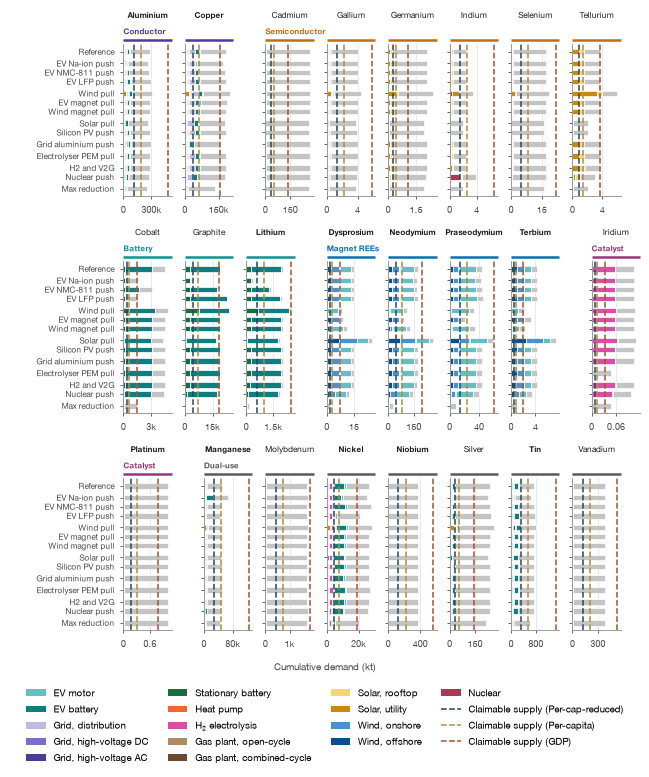

In [6]:
panel_key = "metal_panel"

# This figure's height *is* its scenario axis, so the axis takes the panel spec's
# own smaller gap between scenario groups rather than the shared one.
horizontal_bars = plotting.bar_positions(
    scenario_members, style, gap=style[panel_key]["group_gap"]
)
# One line over each panel, saying both what the metal is and what kind of supply
# stands behind it: there is no room here for the second line Fig. 1 puts the
# second thing on.
metal_panel_title = {
    metal: {"fontsize": style[panel_key]["title_size"], **metal_label_style[metal]}
    for metal in metals
}

fig, axes, bands = plotting.flow_panel_grid(
    grouped,
    horizontal_bars,
    scenario_nice,
    group_color,
    group_nice,
    style,
    panel_key=panel_key,
    value_label="Cumulative demand (kt)",
)

for metal, ax in axes.items():
    granted = {
        method: float(allocated_supply.sel(metal=metal, allocation_method=method))
        for method in methods
    }
    ceiling = demand_panel(
        ax,
        metal,
        scale=1.0,
        levels=granted,
        ylabel="",  # every panel is on its own scale; the figure names the unit once
        bars=bar_order,
        bar_x=horizontal_bars,
        panel_key=panel_key,
        orientation="horizontal",
        named=False,  # the row's own column of names carries them
        subtitle=False,
        title_style=metal_panel_title[metal],
        title_loc="center",  # a name here is nearly as wide as the panel under it
        extra_pad=plotting.band_title_pad(style, panel_key),
        non_energy=True,  # energy-system demand alone; the other figures band it
    )
    ax.set_xlim(0, 1.08 * max(ceiling, *granted.values()))
    plotting.compact_ticks(ax, style, panel_key, "horizontal")

legend = comparison_legend(fig, supply_names=supply_short, non_energy_handles=[])
plotting.save_figure(fig, figures_dir, "demand_and_supply_kt", style, (legend, *bands))

## Fig. 1 — the reference scenario as a share of world supply

One bar per metal, the `base` scenario only, with every quantity divided by that
metal's world supply over the window. That division is what makes the panels
comparable: the axis is shared, and because a principle grants the same
*fraction* of world supply whatever the metal, its line sits at exactly the same
height in every panel and can be read straight across the figure. A bar reaching
its line is a metal whose demand takes the whole of the share that principle
allows; above the line is a shortfall.

Normalising is also what lets the axis stay linear across all fourteen panels:
in these units every bar lands between about 15% and 80%, so nothing has to be
compressed to fit. The energy stack is still a sliver on the metals whose demand
is overwhelmingly other-sector — vanadium's energy demand is 0.1% of world
supply against 37% from everything else — but that is the finding, not the axis.

The two things that decide how firm a line is are named against each panel: the
**end-use group** heads the row, and the **supply-side character** — primary,
co-product, or by-product of the host named beside it — sits under the metal. A
by-product's ceiling is the softest of the three, because its production is a
fraction of another metal's and cannot be raised to meet demand on its own.

`base` is the cost-optimal run at today's market shares; what the other scenarios
do to these bars is Fig. 0.

axis extended past 50% for: Cobalt, Iridium


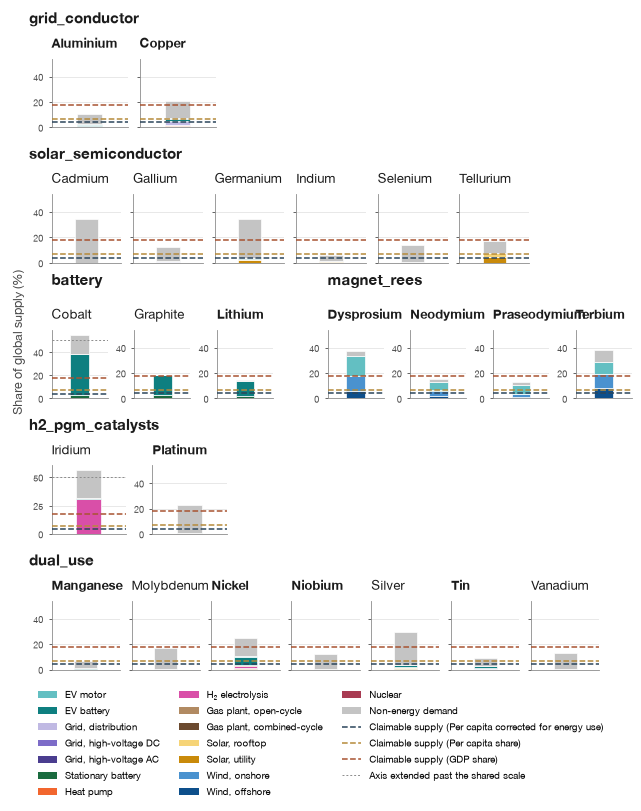

In [7]:
# The one scale that puts every metal on the same axis. What a principle grants
# is the same fraction of world supply whichever metal it is, so its line sits at
# exactly the same height in every panel that keeps the shared scale.
granted = {method: 100 * shares[method] for method in methods}

cap = share_axis["cap_percent"]
if cap <= max(granted.values()):
    raise ValueError(
        f"compare.share_axis.cap_percent is {cap}%, at or below the most generous "
        f"share ({max(granted.values()):.1f}%); its line would leave every panel"
    )

fig, axes, headers = plotting.panel_grid(grouped, style, panel_key="narrow_panel")

ceilings = {}
for metal, ax in axes.items():
    ceilings[metal] = demand_panel(
        ax,
        metal,
        scale=float(total_supply.sel(metal=metal)) / 100,
        levels=granted,
        # At a fifteenth of the page a panel has room for neither its own axis
        # name nor a subtitle, so both are said once for the figure.
        ylabel="",
        bars=[reference],
        bar_x={reference: 0.0},
        panel_key="narrow_panel",
        subtitle=False,
        title_style=metal_label_style[metal],
    )
    ax.set_xticks([])  # one bar per panel, and the panel title already names it

# Panels that fit under the cap share one scale; the rest extend to fit their bar
# rather than truncating it, and mark where the shared scale ran out.
#
# Tick labels then have to go on *every* panel of a row that holds an extended
# panel. Dropping them is only safe while a row is on one scale: a bare panel is
# read against the nearest labelled axis, and if that axis broke out of the shared
# scale the bar beside it reads at roughly twice its real height.
rows = plotting.pack_rows(grouped, style["narrow_panel"]["max_columns"])
for row in rows:
    row_metals = [metal for _, members in row for metal in members]
    row_shared = all(ceilings[metal] <= cap for metal in row_metals)
    for position, metal in enumerate(row_metals):
        ax = axes[metal]
        exceeds = ceilings[metal] > cap
        ax.set_ylim(0, 1.08 * (ceilings[metal] if exceeds else cap))
        if exceeds:
            ax.axhline(
                cap, color=share_axis["exceeded_color"], linewidth=0.7,
                linestyle=(0, (2, 2)), zorder=1,
            )
        if position:
            if row_shared:
                ax.tick_params(labelleft=False)

ylabel = fig.supylabel("Share of global supply (%)", color=style["ink"]["secondary"])
legend = comparison_legend(
    fig,
    ncol=3,
    extra=[
        mlines.Line2D(
            [], [], color=share_axis["exceeded_color"], linewidth=0.7,
            linestyle=(0, (2, 2)), label=share_axis["exceeded_label"],
        )
    ],
)
plotting.save_figure(
    fig, figures_dir, "demand_share_of_world_supply", style,
    (legend, ylabel, *headers),
)

extended = sorted(metal for metal, c in ceilings.items() if c > cap)
print(f"axis extended past {cap}% for: {', '.join(extended) or 'nothing'}")

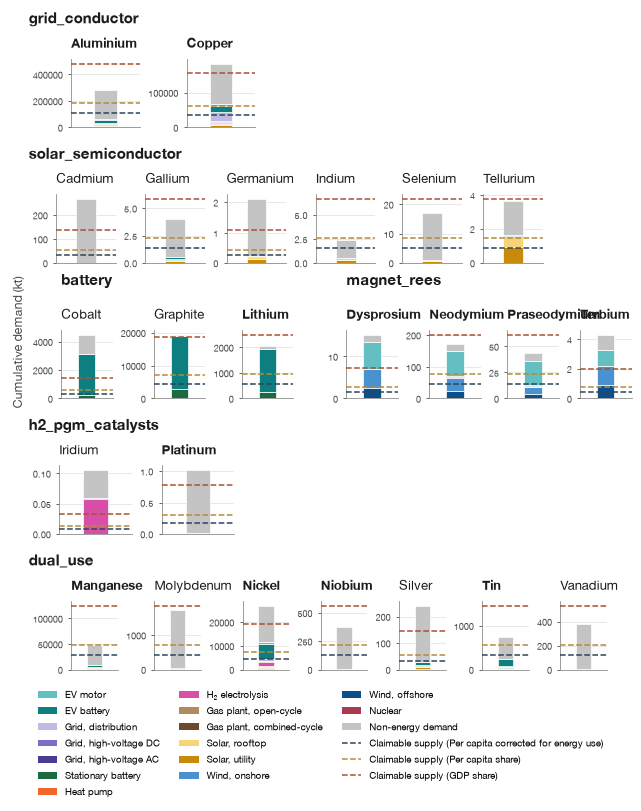

In [8]:
# Same panels, unnormalised: kt means something different in every panel, so each
# is sized to its own bar and ceiling and keeps its tick labels.
fig, axes, headers = plotting.panel_grid(grouped, style, panel_key="narrow_panel")

for metal, ax in axes.items():
    granted_kt = {
        method: float(allocated_supply.sel(metal=metal, allocation_method=method))
        for method in methods
    }
    ceiling = demand_panel(
        ax,
        metal,
        scale=1.0,
        levels=granted_kt,
        ylabel="",  # named once for the figure
        bars=[reference],
        bar_x={reference: 0.0},
        panel_key="narrow_panel",
        subtitle=False,
        title_style=metal_label_style[metal],
    )
    ax.set_xticks([])  # one bar per panel, and the panel title already names it
    ax.set_ylim(0, 1.08 * max(ceiling, *granted_kt.values()))

# The unit is shared even though the scale is not, so it is named once.
ylabel = fig.supylabel("Cumulative demand (kt)", color=style["ink"]["secondary"])
legend = comparison_legend(fig, ncol=3)
plotting.save_figure(
    fig, figures_dir, "demand_and_supply_reference_kt", style,
    (legend, ylabel, *headers),
)

## Fig. 1b — the floor the scenarios stand on

Fig. 1 divides by *world* supply, which makes every panel comparable but leaves
the allocation principle as a line to be read against. This divides by
**allocated** supply instead — the same units as Fig. 2b — so the parity line is
1 and a bar passing it is a shortfall outright. One bar per metal, worst first.

Each bar is split at the only place that matters for what follows:

- **grey** — other-sector demand. No scenario in this study touches it. It is the
  floor everything else stands on, and where it alone passes the line, the metal
  is short before the energy transition asks for any of it.
- **coloured** — the energy transition at the reference scenario, in the metal's
  end-use hue, so a bar here is the same metal as the point of that colour in
  Fig. 2.
- **whisker** — where the top of the bar goes across *every* scenario, not just
  the ones that help. The scenarios can raise a metal as well as lower it, and the
  span is the honest statement of what they reach.

This is the figure Figs. 1 and 2 do not make: it shows the scenarios moving a large
fraction of the energy system's own demand while barely moving the bar, because
on most metals the energy system is the smaller part of the bar. That is not a
reason to ignore other-sector demand — it is what decides which metals a
technology choice can settle at all, and so it sets up Fig. 3.

Read against Fig. 2b: a metal whose whisker crosses the line is one of Fig. 2b's
traces crossing parity, and a metal whose grey floor is already over the line is
one of Fig. 2b's stranded top-left corner.

other sectors alone already exceed allocated supply: Iridium, Cadmium, Germanium, Silver, Platinum
a single scenario brings back under it: Copper, Graphite
whiskers cut at the 10x axis cap: none


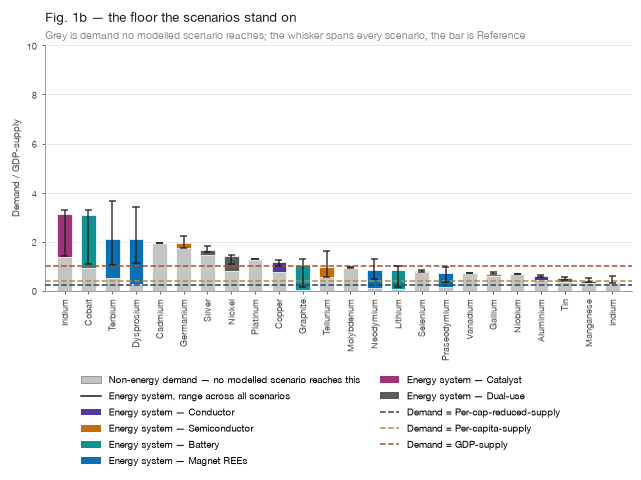

In [9]:
sort_by = floor_style["sort_by"]
if sort_by == "shortfall":
    floor_metals = list(
        placed[MetalPosition.total_over_supply_base].sort_values(ascending=False).index
    )
elif sort_by == "group":
    floor_metals = metals
else:
    raise ValueError(
        f"compare.floor.sort_by is {sort_by!r}; expected 'shortfall' or 'group'"
    )

floor_x = {metal: float(index) for index, metal in enumerate(floor_metals)}
floor_parity = parity_levels(MetalPosition.parity_level_ratio)

# The two segments are columns of the table, not a difference taken here: they
# are what the bar draws, and they sum to total_over_supply_base by construction.
FLOOR_SEGMENT, SCENARIO_SEGMENT = "floor", "scenario"
segments = pd.DataFrame(
    {
        FLOOR_SEGMENT: placed[MetalPosition.non_energy_over_supply],
        SCENARIO_SEGMENT: placed[MetalPosition.energy_over_supply_base],
    }
).reindex(floor_metals)

panel = style["metal_axis"]
fig, ax = plt.subplots(figsize=(panel["width"], panel["height"]), layout="constrained")

# One bar at a time: the floor is grey for every metal, but the segment above it
# takes the metal's own end-use hue, which is what links a bar to its point in
# Fig. 2. stacked_bars keys colour by segment, so the colour varies per call.
for metal in floor_metals:
    plotting.stacked_bars(
        ax,
        floor_x,
        segments.loc[[metal]],
        {
            FLOOR_SEGMENT: non_energy_style["color"],
            SCENARIO_SEGMENT: metal_color[metal],
        },
        style,
        panel_key="metal_axis",
    )

cut = plotting.range_whiskers(
    ax,
    floor_x,
    placed[MetalPosition.total_over_supply_reduced].reindex(floor_metals),
    placed[MetalPosition.total_over_supply_raised].reindex(floor_metals),
    floor_style["whisker"],
    cap=floor_style["cap"],
)
plotting.reference_lines(
    ax, floor_parity, allocation_style, "supply_color", "supply_linestyle"
)
plotting.style_panel(
    ax,
    style,
    title="Fig. 1b — the floor the scenarios stand on",
    subtitle=(
        "Grey is demand no modelled scenario reaches; the whisker spans every "
        f"scenario, the bar is {scenario_nice[reference]}"
    ),
    ylabel=f"Demand / {method_short[reference_method]}-supply",
)
plotting.category_axis(
    ax, floor_x, {m: m for m in floor_metals}, style, panel_key="metal_axis"
)
# The cap is the axis, not a clip on the data: range_whiskers marks whatever
# runs past it. It has to clear the tallest bar, or a bar would be truncated
# with no mark at all.
tallest = placed[MetalPosition.total_over_supply_base].max()
if floor_style["cap"] < tallest:
    raise ValueError(
        f"compare.floor.cap is {floor_style['cap']}, below the tallest bar "
        f"({tallest:.2f}); a bar would be cut off unmarked"
    )
ax.set_ylim(0, floor_style["cap"])

legend = fig.legend(
    handles=[
        mpatches.Patch(
            facecolor=non_energy_style["color"],
            edgecolor=non_energy_style["edge_color"],
            linewidth=0.5,
            label=f"{non_energy_style['nice_name']} — no modelled scenario reaches this",
        ),
        mlines.Line2D(
            [], [],
            color=floor_style["whisker"]["color"],
            linewidth=floor_style["whisker"]["line_width"],
            label="Energy system, range across all scenarios",
        ),
        *plotting.patch_handles(
            grouped, group_color, {g: f"Energy system — {n}" for g, n in group_nice.items()}
        ),
        *plotting.line_handles(
            methods,
            allocation_style,
            {m: f"Demand = {method_short[m]}-supply" for m in methods},
            "supply_color",
            "supply_linestyle",
        ),
    ],
    frameon=False,
    # Two columns, not three: these labels are sentences, and three of them side
    # by side are wider than the page the panel above them is drawn to.
    ncol=2,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.0),
)
plotting.save_figure(fig, figures_dir, "demand_floor_and_scenario_range", style, (legend,))

unreachable = [
    m for m in floor_metals if placed.loc[m, MetalPosition.non_energy_over_supply] > 1
]
resolvable = [
    m
    for m in floor_metals
    if placed.loc[m, MetalPosition.total_over_supply_base] > 1
    and placed.loc[m, MetalPosition.total_over_supply_reduced] <= 1
]
print(f"other sectors alone already exceed allocated supply: {', '.join(unreachable)}")
print(f"a single scenario brings back under it: {', '.join(resolvable)}")
print(f"whiskers cut at the {floor_style['cap']:g}x axis cap: {', '.join(cut) or 'none'}")

## Fig. 1c — every metal on one axis

Fig. 1's panels collapsed onto a single axes: same bars, same normalisation, one
twelfth of the paper. The panel grid draws a y-axis and a set of supply lines
around every single bar; here each principle grants the same *fraction* of world
supply whatever the metal, so its line is drawn once, straight across the figure,
and named at the right-hand edge against the line itself. Any two bars are then
read against each other and against those lines with nothing in between.

Bars are blocked by end-use group, named under the axis, in the order
`mineral_info.csv` lists them.

**The axis stops at `compare.share_axis.cap_percent`.** Fig. 1 gives a panel that
does not fit the shared scale a scale of its own; one axes cannot do that, so the
bar is cut instead — marked with an arrow beside it, in the gap rather than over
the bar, and labelled with where it really reaches. The cap is not a neutral
choice: the bars that overrun are tall because of *other-sector* demand, which no
scenario in this study touches, and an axis fitted to them spends its height on the
one quantity the figure cannot act on. Nothing is hidden by it — what is cut is
named on the figure and printed under the cell.

Three things are said in how a mark is drawn rather than in a mark of their own,
because a mark costs room the bars need:

- **how well the other-sector band is known** — the region is charged a world
  series times a share measured per metal (`rules/ned.smk`), and the band takes
  the weaker of the two ratings. It is drawn solid where the metal has its own
  MSA chapter behind a projected world series, paler where the share is inherited
  from an aggregate (the magnet REEs, one share for four elements), and palest
  where MSA does not cover the metal at all and the metal-blind GDP share stands
  in, or where the world series is one reference year held flat (graphite). The
  height is the same quantity in every case, so the encoding stays inside the
  band's own grey rather than taking a second hue.
  `compare.non_energy.confidence` holds the three fills.
- **the metal's supply-side character** — its name is set in strong upright ink
  where output can be raised on its own account (*primary / co-product*) and in
  quiet slanted ink where it cannot, being a fraction of another metal's
  (*by-product*). Two classes, not the four readings behind them
  (`compare.metal_types`): a ramp through four invites the eye to read a degree
  where the thing that matters is a division, and the same two are what Fig. 2c
  gives its marker shapes to and Fig. 3c its column names.
  `compare.metal_type_classes` holds how each is written.
- **which supply is which** — the three lines carry the short name of their
  allocation principle (`compare.allocation_style.<method>.nice_name`), not the
  published one from `data/allocation_factors_eu.csv`.

There is no title: the caption belongs where the figure is published.

axis capped at 50%; bars cut: Cobalt, Iridium
other-sector band, high: Aluminium, Cobalt, Copper, Gallium, Germanium, Graphite, Indium, Lithium, Manganese, Nickel, Niobium, Platinum, Vanadium
other-sector band, medium: Dysprosium, Neodymium, Praseodymium, Terbium
other-sector band, low: Cadmium, Iridium, Molybdenum, Selenium, Silver, Tellurium, Tin


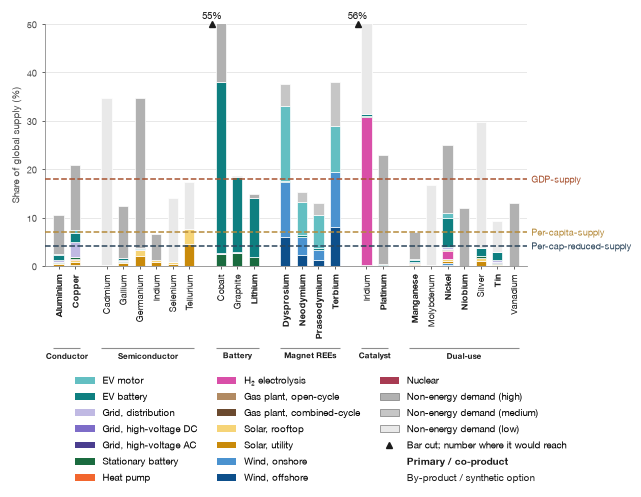

In [10]:
granted = {method: 100 * shares[method] for method in methods}
cap = share_axis["cap_percent"]
if cap <= max(granted.values()):
    raise ValueError(
        f"compare.share_axis.cap_percent is {cap}%, at or below the most generous "
        f"share ({max(granted.values()):.1f}%); its line would leave the axis"
    )

# Every quantity as a percentage of that metal's world supply over the window.
scale = total_supply.to_pandas().reindex(metals) / 100
energy = (
    demand.sel(scenario=reference)
    .to_series()
    .unstack("technology")
    .reindex(index=metals, columns=technologies)
    .div(scale, axis=0)
)
# One band per metal: other-sector demand varies with neither the scenario nor
# the allocation principle.
other_sectors = pd.DataFrame(
    {NON_ENERGY_SEGMENT: other_sector_demand.to_pandas().reindex(metals) / scale}
)

# How well that band's own height is known, written into how it is filled. The
# region's share of world other-sector demand is measured per metal (rules/ned.smk)
# and how well depends on what MSA covers: the metal itself, an aggregate it
# travels inside, or nothing, in which case the metal-blind GDP share stands in.
# It is the same quantity either way, so the band keeps its grey and varies only
# in strength — solid at full colour, washed out and hatched as the basis weakens.
confidence_style = non_energy_style["confidence"]
band_style = {
    level: {"facecolor": spec["color"], "hatch": spec["hatch"]}
    for level, spec in confidence_style.items()
}
# The fill is all a bar may carry. Every segment on this axes is edged with the
# shared white hairline, which is the page's own colour and so eats into the bar
# rather than showing outside it; an edge in any other colour is drawn at the same
# width and read as a wider bar (plotting.FOOTPRINT_KEYS refuses one). The key sits
# on no shared axis, so its swatch is outlined instead — without it the palest of
# the three greys has no boundary against the page.
band_key_style = {
    level: {
        **spec,
        "edgecolor": non_energy_style["edge_color"],
        "linewidth": style["bar"]["edge_width"],
    }
    for level, spec in band_style.items()
}
band_confidence = non_energy["confidence"].to_series().reindex(metals)
unstyled = sorted(set(band_confidence) - set(band_style))
if unstyled:
    raise ValueError(
        f"the non-energy cube carries confidence {unstyled}, which "
        "compare.non_energy.confidence gives no way to draw"
    )
# Only the levels the metals on this figure actually use, strongest first: three
# entries in the key where the bars carry two would say the band means something
# it does not.
band_levels = [level for level in band_style if level in set(band_confidence)]
band_label = {
    level: f"{non_energy_style['nice_name']} ({confidence_style[level]['nice_name']})"
    for level in band_levels
}

panel = style["metal_axis"]
fig, ax = plt.subplots(figsize=(panel["width"], panel["height"]), layout="constrained")
metal_x = plotting.bar_positions(grouped, style)

top = plotting.stacked_bars(
    ax, metal_x, energy, technology_color, style, panel_key="metal_axis"
)
top = plotting.stacked_bars(
    ax, metal_x, other_sectors, non_energy_color, style,
    bottom=top, panel_key="metal_axis",
    row_styles={metal: band_style[level] for metal, level in band_confidence.items()},
)
line_names = plotting.reference_lines(
    ax, granted, allocation_style, "supply_color", "supply_linestyle",
    labels={method: f"{method_short[method]}-supply" for method in methods},
)
# No title: the caption is written where the figure is published.
plotting.style_panel(
    ax, style, title=None, ylabel="Share of global supply (%)"
)
plotting.category_axis(
    ax, metal_x, {m: m for m in metals}, style,
    panel_key="metal_axis", label_styles=metal_label_style,
)
group_names = plotting.group_axis(
    ax, metal_x, grouped, group_nice, style, panel_key="metal_axis"
)

# The cap is the axis, not a clip on the data: overrun_marks says of every bar it
# cuts that it is cut, and where it reaches.
ax.set_ylim(0, cap)
overrun = share_axis["overrun"]
cut, cut_marks = plotting.overrun_marks(
    ax, metal_x, pd.Series(top, index=energy.index), cap, overrun,
    style, panel_key="metal_axis",
)

# The supply lines are named on the axis, so they are not in the key. What is in
# it instead is how the other-sector band is filled and how the metal names are
# set, which are the figure's two unmarked encodings.
legend = comparison_legend(
    fig,
    ncol=3,
    supply_lines=False,
    non_energy_handles=plotting.styled_patch_handles(band_levels, band_key_style, band_label),
    extra=[
        mlines.Line2D(
            [], [], color=overrun["color"], marker="^", linestyle="none",
            markersize=overrun["marker_size"], label=overrun["legend_label"],
        ),
        *[
            mlines.Line2D([], [], linestyle="none", marker="", label=label)
            for label in class_key
        ],
    ],
)
for text in legend.get_texts():
    if text.get_text() in class_key:
        text.set(**class_label_style[class_key[text.get_text()]])

plotting.save_figure(
    fig, figures_dir, "demand_share_of_world_supply_one_axis", style,
    (legend, *line_names, *group_names, *cut_marks),
)

print(f"axis capped at {cap}%; bars cut: {', '.join(cut) or 'none'}")
for level in band_levels:
    named = ", ".join(band_confidence[band_confidence == level].index)
    print(f"other-sector band, {confidence_style[level]['nice_name']}: {named}")

## Fig. 1d — Fig. 1c turned on its side

Same bars, same normalisation, same cap, same key; only which axis carries which,
which is one `orientation` argument to every helper that draws into the panel.

The turn buys the metal names: level and read in one pass down a column, with the
end-use blocks named beside them. The bar axis is then the page's *height*, bought
rather than divided up (`plotting.metal_axis_turned.bar_pitch`), so a
twenty-fifth metal lengthens the figure instead of narrowing every bar on it.

It costs the value axis. The supply lines stand up and carry their names over the
panel, level, in rows filling from the right so that no line rises through another
name. Written under its own file name, beside the published Fig. 1.

axis capped at 50%; bars cut: Cobalt, Iridium


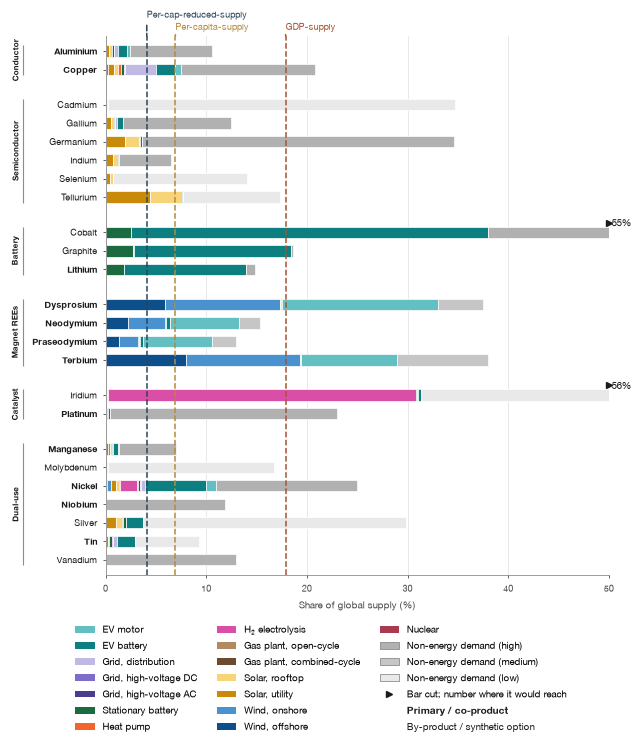

In [11]:
# Drawn from the cell above; what is here is the turn itself.
panel_key = "metal_axis_turned"
turned_x = plotting.bar_positions(grouped, style)
fig, ax = plt.subplots(
    figsize=plotting.turned_figure_size(turned_x, style, panel_key),
    layout="constrained",
)

top = plotting.stacked_bars(
    ax, turned_x, energy, technology_color, style,
    panel_key=panel_key, orientation="horizontal",
)
top = plotting.stacked_bars(
    ax, turned_x, other_sectors, non_energy_color, style,
    bottom=top, panel_key=panel_key, orientation="horizontal",
    row_styles={metal: band_style[level] for metal, level in band_confidence.items()},
)
# Before the names below, which are packed against the value axis's own scale.
ax.set_xlim(0, cap)

turned_line_names = plotting.reference_lines(
    ax, granted, allocation_style, "supply_color", "supply_linestyle",
    labels={method: f"{method_short[method]}-supply" for method in methods},
    orientation="horizontal",
)
# No title: the caption is written where the figure is published.
plotting.style_panel(
    ax, style, title=None, ylabel="Share of global supply (%)",
    orientation="horizontal",
)
plotting.category_axis(
    ax, turned_x, {m: m for m in metals}, style,
    panel_key=panel_key, orientation="horizontal", label_styles=metal_label_style,
)
turned_group_names = plotting.group_axis(
    ax, turned_x, grouped, group_nice, style, panel_key=panel_key,
    orientation="horizontal",
)

turned_cut, turned_cut_marks = plotting.overrun_marks(
    ax, turned_x, pd.Series(top, index=energy.index), cap, overrun,
    style, panel_key=panel_key, orientation="horizontal",
)

# Fig. 1c's key, its arrow turned with the bars.
legend = comparison_legend(
    fig,
    ncol=3,
    supply_lines=False,
    non_energy_handles=plotting.styled_patch_handles(band_levels, band_key_style, band_label),
    extra=[
        mlines.Line2D(
            [], [], color=overrun["color"], marker=">", linestyle="none",
            markersize=overrun["marker_size"], label=overrun["legend_label"],
        ),
        *[
            mlines.Line2D([], [], linestyle="none", marker="", label=label)
            for label in class_key
        ],
    ],
)
for text in legend.get_texts():
    if text.get_text() in class_key:
        text.set(**class_label_style[class_key[text.get_text()]])

plotting.save_figure(
    fig, figures_dir, "demand_share_of_world_supply_one_axis_turned", style,
    (legend, *turned_line_names, *turned_group_names, *turned_cut_marks),
)

print(f"axis capped at {cap}%; bars cut: {', '.join(turned_cut) or 'none'}")

## Fig. 2 — every metal at once, and where the scenarios can take it

Figs. 0 and 1 give each metal a panel, which is fourteen drawings to compare by
eye. Fig. 2 collapses each metal to a single point on two axes and traces it
from the reference scenario to the least energy-system demand any scenario
leaves it with:

- **y** — how far demand outruns the supply the region may claim.
- **x** — how much of that demand the modelled energy transition *is*, i.e. how
  much of the problem the scenarios reach at all.
- **→** — the trace, from `base` to that metal's lowest-demand scenario.

Both readings of y divide by the supply one **reference principle** grants
(`compare.reference_method`, the most generous of the three). A
principle grants the same *fraction* of world supply whatever the metal, so
switching to a stricter one multiplies every point's y by a constant and leaves
the arrangement untouched — which is why the other two principles come in as
horizontal parity lines rather than as a second and third copy of the cloud.
A point above a line is a shortfall under that principle; the highest line is
the most generous, so anything above it is a shortfall under all three.

The two panels share the axes and the parity lines but not their **colour and
shape**, because they are asked to say different things (`position_figure`
takes both, and which end of the trace is filled, from its caller):

- Fig. 2a — colour is the end-use group, matching the row headings above, and
  shape is the supply-side character in the four classes of
  `compare.metal_types`. The filled end is where the metal stands today.
- Fig. 2b — colour is the **scenario** the metal reaches its lowest demand in (`scenarios.<scenario>.color`), and shape is the same
  supply-side character read in the two classes of
  `compare.metal_type_classes`. The filled end is where the scenario takes it.

The supply-side character is the one thing here that is not on an axis: a
by-product's ceiling is the softest of the three, because its production is a
fraction of another metal's and cannot be raised to meet demand on its own.

Every quantity drawn is a column of `build/compare/metal_positions.csv`
(`build_metal_positions`), one row per (metal, allocation principle).

**The reduced end is an envelope, not a world.** Each metal minimises in a
different scenario — cobalt under Na-ion, dysprosium under wind pull, germanium
under solar pull — and several of those conflict. Read the trace as *the most
any single scenario in this scenario set removes*, not as a portfolio.

In [12]:
def position_figure(
    y_base,
    y_reduced,
    parity_column,
    *,
    x_reduced,
    reduced_label,
    title,
    subtitle,
    ylabel,
    log_y,
    quadrant_notes,
    name,
    label_lines,
    colors,
    markers,
    filled_end,
    key_handles,
):
    """The scatter both readings of the y axis share.

    `y_base`/`y_reduced` are the MetalPosition columns the trace runs between
    and `x_reduced` where it ends on the x axis; `parity_column` is the column
    carrying where each principle's parity sits on that same y axis. x is always
    the energy system's share of total demand, since that is the axis every
    reading has in common, and `reduced_label` says what the reduced end *is*,
    which differs between a single scenario and a combination of them.
    `quadrant_notes=None` draws no crosshair at all, for a figure that classifies
    the metals by mark rather than by corner.

    What a mark's colour and shape stand for is the figure's own — `colors`,
    `markers`, and the `key_handles` naming them — as is which end of the trace
    is filled and whether the parity lines are named where they are drawn
    (`label_lines`, as Fig. 1c names them) or left to the key. The axes, the parity lines and the quadrant split are shared,
    since those are what let the two figures be read against each other.
    """
    frame = pd.DataFrame(
        {
            "x": placed[MetalPosition.energy_share_of_demand_base_percent],
            "y": placed[y_base],
            "x_to": placed[x_reduced],
            "y_to": placed[y_reduced],
        }
    )
    levels = parity_levels(parity_column)

    panel = positions_style["panel"]
    fig, ax = plt.subplots(
        figsize=(panel["width"], panel["height"]), layout="constrained"
    )
    plotting.style_scatter(
        ax,
        style,
        title=title,
        subtitle=subtitle,
        xlabel="Energy system's share of the region's total demand (%)",
        ylabel=ylabel,
        log_y=log_y,
    )

    # Limits before anything is drawn: traced_points sizes its "too short to
    # mark" threshold off the x range, and the quadrant notes sit in the corners.
    # The panel runs wider than the data on the left so that label_points can put
    # a crowded name to the *left* of its marker; the axis is still ticked over
    # the 0-100 a share actually spans.
    ax.set_xlim(*positions_style["x_limits"])
    ax.set_xticks(range(0, 101, 20))
    low = min(frame[["y", "y_to"]].min().min(), min(levels.values()))
    high = max(frame[["y", "y_to"]].max().max(), max(levels.values()))
    ax.set_ylim(low / 1.9, high * 1.9) if log_y else ax.set_ylim(0, high * 1.12)

    # A line spanning the whole panel is read where it is, so its name belongs
    # against it rather than in a key three rows long -- but only on a figure
    # whose right margin is empty enough to carry three of them.
    line_names = plotting.reference_lines(
        ax, levels, allocation_style, "supply_color", "supply_linestyle",
        labels=(
            {m: f"{method_short[m]}-supply" for m in methods}
            if label_lines
            else None
        ),
    )
    # A figure whose marks already carry the classification passes no notes:
    # the crosshair would then be a second, competing division of the same panel.
    if quadrant_notes is not None:
        plotting.quadrant_split(
            ax,
            positions_style["quadrants"]["energy_share_percent"],
            levels[reference_method],
            positions_style["quadrants"],
            quadrant_notes,
        )
    plotting.traced_points(
        ax,
        frame,
        colors,
        markers,
        positions_style["trace"],
        style["ink"],
        filled_end=filled_end,
    )
    plotting.label_points(
        ax, frame, {m: m for m in metals}, colors, positions_style["label"]
    )

    # The end a figure fills is the end it is about, so the key that says which
    # is which is built from `filled_end` rather than written out per figure.
    end_label = {
        "base": f"{scenario_nice[reference]} scenario",
        "reduced": reduced_label,
    }
    legend = fig.legend(
        handles=[
            *key_handles,
            *(
                []
                if label_lines
                else plotting.line_handles(
                    methods,
                    allocation_style,
                    {m: f"Demand = {method_short[m]}-supply" for m in methods},
                    "supply_color",
                    "supply_linestyle",
                )
            ),
            *[
                mlines.Line2D(
                    [], [], color=style["ink"]["secondary"], marker="o",
                    linestyle="none", markersize=6,
                    markerfacecolor=(
                        style["ink"]["secondary"]
                        if end == filled_end
                        else style["ink"]["surface"]
                    ),
                    label=label,
                )
                for end, label in end_label.items()
            ],
        ],
        frameon=False,
        ncol=3,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.0),
    )
    plotting.save_figure(fig, figures_dir, name, style, (legend, *line_names))
    return frame


print("the lowest-demand scenario each metal traces to:")
print(
    placed[[MetalPosition.scenario_percent, MetalPosition.reduced_scenario]]
    .assign(**{str(MetalPosition.reduced_scenario): lambda f: [
        scenario_nice[s] for s in f[MetalPosition.reduced_scenario]
    ]})
    .round(1)
    .to_string()
)

the lowest-demand scenario each metal traces to:
              scenario_percent       reduced_scenario
metal                                                
Aluminium                 26.3         EV Na-ion push
Cadmium                   97.9        Silicon PV push
Cobalt                    93.1         EV Na-ion push
Copper                    40.3    Grid aluminium push
Dysprosium                52.4              Wind pull
Gallium                   40.1             Solar pull
Germanium                 90.0             Solar pull
Graphite                  84.8         EV Na-ion push
Indium                    95.8        Silicon PV push
Iridium                   97.9  Electrolyser PEM pull
Lithium                   87.2         EV Na-ion push
Manganese                 33.5            EV LFP push
Molybdenum                 1.4             Solar pull
Neodymium                 51.5         EV magnet pull
Nickel                    48.3            EV LFP push
Niobium                   12.8   

### Fig. 2a — energy-system demand against allocated supply

y is the energy transition's demand alone as a percentage of allocated supply —
Fig. 1's bar height, one metal per point. x is that same demand as a share of
everything the region wants the metal for. The y axis is log: the metals span
0.7% to 274% of allocated supply, three and a half orders of magnitude, and a
linear axis would put ten of the fourteen on the floor.

Read this as *how much of the region's allocated supply the transition alone
asks for, and how much of the metal's story that is*. Cobalt, dysprosium and
gallium ask for more of it than the most generous principle grants, before any
other sector is served.

**Both axes divide the same energy-system demand**, so they are not independent:
the rank correlation is about 0.9 and the points sit on a diagonal. The cell
below prints it. Fig. 2b keeps the x axis and changes the numerator of y, which
is what separates the two questions — see the note there.

rank correlation between the two axes: 0.91


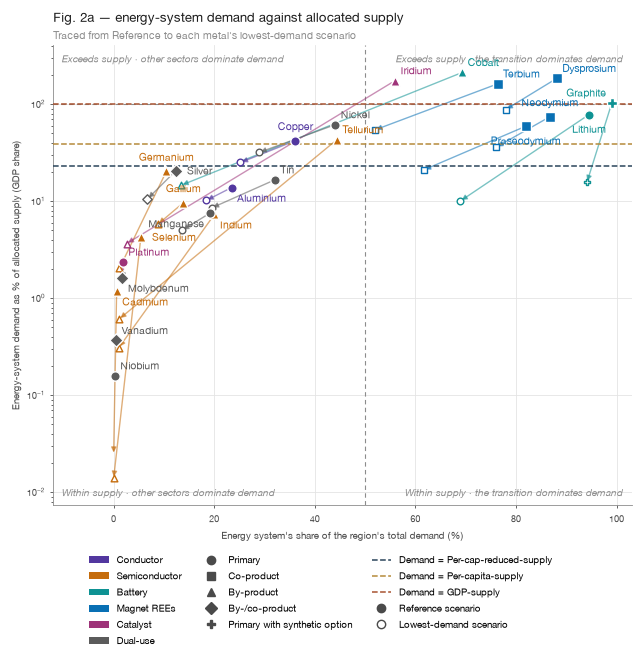

In [13]:
energy_placed = position_figure(
    MetalPosition.energy_over_supply_base_percent,
    MetalPosition.energy_over_supply_reduced_percent,
    MetalPosition.parity_level_percent,
    x_reduced=MetalPosition.energy_share_of_demand_reduced_percent,
    reduced_label="Lowest-demand scenario",
    title="Fig. 2a — energy-system demand against allocated supply",
    subtitle=(
        f"Traced from {scenario_nice[reference]} to each metal's "
        "lowest-demand scenario"
    ),
    ylabel=(
        "Energy-system demand as % of allocated supply "
        f"({method_nice[reference_method]})"
    ),
    log_y=True,
    quadrant_notes={
        "upper left": "Exceeds supply · other sectors dominate demand",
        "upper right": "Exceeds supply · the transition dominates demand",
        "lower left": "Within supply · other sectors dominate demand",
        "lower right": "Within supply · the transition dominates demand",
    },
    name="metal_positions_energy_demand",
    label_lines=False,
    colors=metal_color,
    markers=metal_marker,
    # The figure is about where the metals stand, so that is the end it fills.
    filled_end="base",
    key_handles=[
        *plotting.patch_handles(grouped, group_color, group_nice),
        *plotting.marker_handles(
            metal_types,
            type_marker,
            {k: spec["nice_name"] for k, spec in metal_types.items()},
            style["ink"]["secondary"],
        ),
    ],
)

# The correlation is the figure's own caveat, so it is printed rather than
# asserted: both axes divide the same energy-system demand.
ranks = energy_placed[["x", "y"]].rank()
print(f"rank correlation between the two axes: {ranks['x'].corr(ranks['y']):.2f}")

### Fig. 2b — total demand against allocated supply

The same x axis, but y is now **every sector's** demand over allocated supply,
not the energy system's alone. Three things change, and they are why this is the
version to read.

**Parity becomes a real line.** Above 1 the region's allocated supply does not
cover the demand charged to it; the trace crossing 1 is an event rather than a
gradient. Only cobalt, lithium and nickel cross it.

**The axes stop measuring the same thing.** Fig. 2a's y and x share the
numerator, so they rank the metals near-identically and the cloud collapses onto
a diagonal. Dividing the *total* breaks that: the two axes come out rank-
correlated at about 0.0, and the four quadrants separate.

**The corners each say something different.**

- *Top left* — a shortfall the modelled scenarios cannot reach. Platinum, manganese,
  vanadium, iridium and germanium are all short, and for each of them the energy
  transition is under 13% of demand, so no technology choice in this scenario set
  moves them. These need supply-side action or other-sector demand reduction.
- *Top right* — a shortfall the energy system can act on. Cobalt and lithium sit
  here and both drop out; dysprosium, gallium, neodymium and praseodymium sit
  here with a substantial scenario that is not substantial enough.
- *Bottom* — aluminium alone, already covered.

The trace decomposes cleanly on these axes: its horizontal travel is the scenario
times the energy share, and its vertical travel is what that buys against the
ceiling. A long flat arrow is a metal whose demand can be restructured without
easing the constraint.

**This panel is drawn as a scenario figure**, which is what separates it from
Fig. 2a rather than the axis alone:

- The **filled** end of each trace is the lowest-demand scenario and the hollow
  end the reference, so what the figure argues — where the metals can get to —
  is what the solid marks say, and today is the mark the trace leaves behind.
- **Colour is the scenario**, not the metal's end-use group: every trace is drawn
  in the colour of the scenario it reaches, so a scenario pulling several metals at
  once shows up as a colour repeated across the cloud. The groups are on
  Figs. 0, 1, 1b and 2a, so nothing is lost by spending colour here.
- **Shape is the supply-side character in two classes** — can production be
  raised to answer demand on its own, or only as a fraction of another metal's.
  Four shapes cannot be told apart on a panel already carrying nine colours;
  molybdenum, silver and vanadium are multi-source but by-product for most of
  their production, so they read with the by-products.

The panel carries no title: the caption is written where the figure is
published, as on Fig. 1c.

The caveats of Fig. 2a all still apply: the reduced end is an envelope, the
principle chosen sets the height of the parity line, and the five metals in the
top-left corner are disproportionately the `low`-confidence supply projections.

brought under GDP share parity by the scenarios: Copper, Graphite
still short at every metal's best scenario: Cadmium, Cobalt, Dysprosium, Germanium, Iridium, Nickel, Platinum, Silver, Terbium


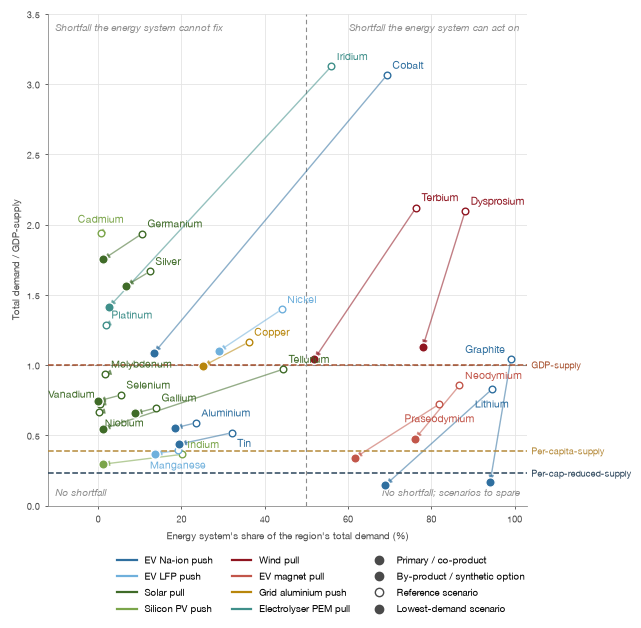

In [14]:
total_placed = position_figure(
    MetalPosition.total_over_supply_base,
    MetalPosition.total_over_supply_reduced,
    MetalPosition.parity_level_ratio,
    x_reduced=MetalPosition.energy_share_of_demand_reduced_percent,
    reduced_label="Lowest-demand scenario",
    # No title: the caption is written where the figure is published.
    title=None,
    subtitle=None,
    ylabel=f"Total demand / {method_short[reference_method]}-supply",
    log_y=False,
    quadrant_notes={
        "upper left": "Shortfall the energy system cannot fix",
        "upper right": "Shortfall the energy system can act on",
        "lower left": "No shortfall",
        "lower right": "No shortfall; scenarios to spare",
    },
    name="metal_positions_total_demand_by_scenario",
    # Named at the right edge, in their own colour, as on Fig. 1c.
    label_lines=True,
    colors=metal_scenario_color,
    markers=metal_class_marker,
    # The figure is about where the scenarios can take the metals, so that is the
    # end it fills: the reference is the hollow mark the trace leaves behind.
    filled_end="reduced",
    key_handles=[
        *[
            mlines.Line2D(
                [], [],
                color=scenario_color[scenario],
                linewidth=1.6,
                label=scenario_nice[scenario],
            )
            for scenario in traced_scenarios
        ],
        *plotting.marker_handles(
            metal_type_classes,
            class_marker,
            {k: spec["nice_name"] for k, spec in metal_type_classes.items()},
            style["ink"]["secondary"],
        ),
    ],
)

crosses = total_placed[(total_placed["y"] > 1) & (total_placed["y_to"] <= 1)]
stuck = total_placed[(total_placed["y"] > 1) & (total_placed["y_to"] > 1)]
print(f"brought under {method_nice[reference_method]} parity by the scenarios: "
      f"{', '.join(crosses.index) or 'nothing'}")
print(f"still short at every metal's best scenario: {', '.join(stuck.index)}")

### Fig. 2c — whose problem each shortfall is

Fig. 2b traces each metal to its best **single** scenario, because every scenario in
the set is one world and a figure reading them one at a time can say nothing
else. But the scenarios are not all alternatives: LFP batteries, aluminium
conductors, induction motors and a different network are separate decisions, and
one world can make several of them. This traces to the least demand any feasible
combination leaves the metal with (`build_max_reduction`) — same axes, same
parity lines, same filled end, so the two panels read against each other and the
difference between them is what combining buys.

Tracing to *everything the scenarios can do* is what turns the panel into a
classification. A metal still above parity there is not short because the wrong
technology was chosen; it is short whatever is chosen. So **colour is the
cluster** (`MetalPosition.cluster`, decided in `build_metal_positions` and named
and coloured in `compare.positions.cluster`) — not a severity ranking but an
answer to *whose problem this is*, reached by two cuts the panel itself draws:

- **Covered — monitor** — allocated supply already carries every sector's demand
  at the reference. Nothing here is a decision; the scenarios only move these around
  underneath the ceiling.
- **Energy policy can close it** — short at the reference, and a combination of
  scenarios in this study brings it under. The shortfall is a design question and the
  answer is in the scenario set: copper, lithium, dysprosium, terbium.
- **Shared gap — supply must expand too** — still above parity when every scenario
  that composes is pulled together, *and* the energy system is a material share of
  the demand (the x cut, `compare.cluster.energy_share_percent`). Cobalt and
  nickel land within a tenth of parity and technology choice takes them most of
  the way; silver and platinum barely move. Either way the transition is a large
  claimant on a gap it cannot close alone.
- **Not the energy system's to fix** — still above parity, and the transition is
  a few percent of the demand or less. The scarcity is real, but no energy-system
  scenario reaches it however aggressive: the remedy is other-sector demand,
  recycling and by-product recovery. Seven of the twenty-three.

The first cut is measured against the most favourable case, so it is deliberately
generous: a metal is only called unclosable where technology choice provably
cannot get it there. Parity is 1 on those ratios by construction, so that cut
needs no threshold. The second does, and it is 10%, sitting in an empty gap that
runs from 4.7% (gallium) to 12.8% (platinum) — `build_metal_positions` prints
where the gap is, so the number can be checked rather than believed. Both cuts
move with the allocation principle, and the cluster is written per principle for
that reason; the panel is drawn against `compare.reference_method`, the most
generous of the three.

The bottom two clusters split along x rather than along y, which is the change
from reading the panel as a ladder. Platinum at 4.1× and selenium at 1.1× are
both past what technology choice can do, so ranking them by residue would say
nothing a policymaker could act on; ranking them by *who has to act* does. How
large the residue is stays the y axis's job.

There is no quadrant crosshair here, unlike Figs. 2a and 2b: the marks carry the
classification, and a crosshair would divide the same panel a second, different
way — the x cut is already a vertical division of the bottom of the panel, and
drawing it as well would double it.

**The reduced end is more of an envelope than Fig. 2b's, not less.** Each metal
takes the combination that suits it, and those disagree across metals — the
combination that empties cobalt is not the one that empties neodymium. Read it as
*how far the scenarios in this study can push this metal*, and not as a portfolio
anyone could adopt.

     Within allocated supply: Aluminium, Gallium, Indium, Lithium, Manganese, Molybdenum, Neodymium, Niobium, Praseodymium, Selenium, Tellurium, Tin, Vanadium
 Closed by technology choice: Cobalt, Copper, Dysprosium, Graphite, Terbium
     Short in every scenario: Nickel
 Short before the transition: Cadmium, Germanium, Iridium, Platinum, Silver

the combination each metal traces to, worst-off first:
                                                                                scenarios  single_reduction_percent  reduction_percent  extra_reduction_percent
metal                                                                                                                                                          
Iridium                                                             Electrolyser PEM pull                      97.9               97.9                      0.0
Cobalt                                                        Solar pull + EV Na-ion push                      93.1 

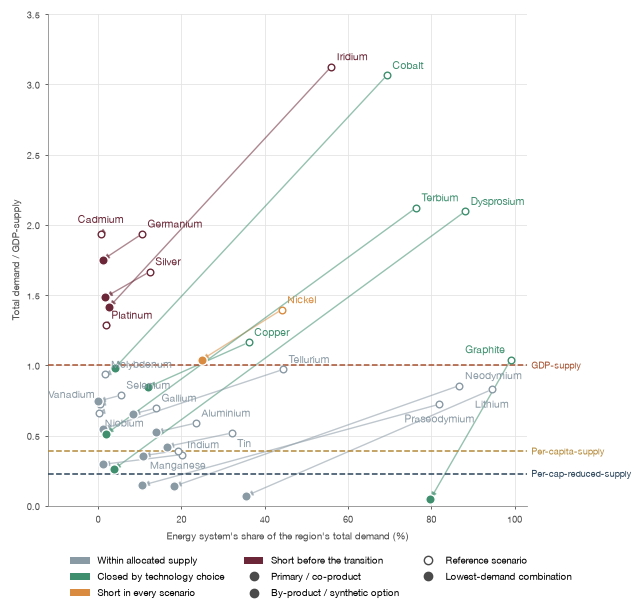

In [15]:
combined_placed = position_figure(
    MetalPosition.total_over_supply_base,
    MetalPosition.total_over_supply_combined,
    MetalPosition.parity_level_ratio,
    x_reduced=MetalPosition.energy_share_of_demand_combined_percent,
    reduced_label="Lowest-demand combination",
    # No title: the caption is written where the figure is published.
    title=None,
    subtitle=None,
    ylabel=f"Total demand / {method_short[reference_method]}-supply",
    log_y=False,
    # The marks carry the classification, so the crosshair would divide the panel
    # a second, competing way.
    quadrant_notes=None,
    name="metal_positions_total_demand_combined",
    label_lines=True,
    # Colour is what the position asks of policy. A trace ending in several
    # decisions at once has no one scenario colour to take (Fig. 2b's reading),
    # and the end-use group is already on Figs. 0, 1, 1b and 2a.
    colors=metal_cluster_color,
    markers=metal_class_marker,
    # The figure is about where the scenarios can take the metals, as Fig. 2b is.
    filled_end="reduced",
    key_handles=[
        *plotting.patch_handles(occupied_clusters, cluster_color, cluster_nice),
        *plotting.marker_handles(
            metal_type_classes,
            class_marker,
            {k: spec["nice_name"] for k, spec in metal_type_classes.items()},
            style["ink"]["secondary"],
        ),
    ],
)

combinations = pd.read_csv(paths["max_reduction"]).set_index(str(MaxReduction.metal))


def combination_name(metal):
    """The scenarios one metal's combination is made of, named as the figures name them.

    The system scenario is only a decision where it is not the reference one, and
    a metal no scenario improves has no decisions at all.
    """
    row = combinations.loc[metal]
    world = row[MaxReduction.system_scenario]
    substitution = row[MaxReduction.substitution_scenarios]
    scenarios = [world] if world != reference else []
    # An empty cell of scenarios reads back as a missing value, not as "".
    if isinstance(substitution, str):
        scenarios += substitution.split(SCENARIO_SEPARATOR)
    return " + ".join(scenario_nice[scenario] for scenario in scenarios) or "none"


for cluster in occupied_clusters:
    members = [m for m in metals if metal_cluster[m] == cluster]
    print(f"{cluster_nice[cluster]:>28}: {', '.join(members)}")

print("\nthe combination each metal traces to, worst-off first:")
ordered = combined_placed.sort_values("y", ascending=False).index
print(
    combinations.reindex(ordered)
    .assign(scenarios=[combination_name(m) for m in ordered])[
        [
            "scenarios",
            MaxReduction.single_reduction_percent,
            MaxReduction.reduction_percent,
            MaxReduction.extra_reduction_percent,
        ]
    ]
    .round(1)
    .to_string()
)

# What combining buys over the single scenario Fig. 2b traces to, in the only unit
# that matters here: metals that cross parity because of it.
single_crosses = set(
    total_placed[(total_placed["y"] > 1) & (total_placed["y_to"] <= 1)].index
)
crosses = set(
    combined_placed[(combined_placed["y"] > 1) & (combined_placed["y_to"] <= 1)].index
)
print(
    f"\nbrought under {method_nice[reference_method]} parity by one scenario: "
    f"{', '.join(sorted(single_crosses)) or 'nothing'}"
)
print(
    f"brought under it only by combining: "
    f"{', '.join(sorted(crosses - single_crosses)) or 'nothing'}"
)

## Fig. 3 — which scenario to choose

Fig. 2 asks which metals are short and which of them the energy system reaches at
all. Fig. 1b shows how much of each metal's bar the scenarios can actually move.
This asks the question those two set up: **given that, which scenario is worth
pulling?**

Answering it needs a unit in which a move on aluminium and a move on iridium are
the same size. That unit is **percentage points of allocated supply** — the change
in demand divided by what the reference principle grants the region — so a scenario
worth a point relieves one percent of the ceiling, whichever metal it does it on.
Everything below is in those units, and every number is a change against the
reference scenario.

Two things shape the answer, and both come out of the data rather than being
imposed on it.

**No scenario is free.** Every scenario that relieves one metal loads another,
because the energy system has to be built out of something: capacity pushed away
from wind lands on solar, a battery chemistry without cobalt has more manganese
in it. Fig. 3a is that trade in two numbers; Fig. 3b is the whole of it.

**Scenarios are of two kinds.** Four scenarios build a *different energy system* —
another network scenario, or an MGA run pushed off the cost optimum. Six build
the same system out of *different sub-technologies*. Those are different
decisions, made by different people, at different cost to the system, and the
config declares which is which (`scenarios.<name>.scenario_type`, checked against
how the scenario is actually built by `check_scenario_types`).

Both figures read `build/compare/scenario_effects.csv` and
`build/compare/scenario_summary.csv` (`build_scenario_effects`).

**One caveat throughout.** A substitution scenario costs the energy system nothing
*here* because its market shares are imposed rather than re-optimised, while an
MGA pull carries a real cost penalty by construction. So the two kinds are not
priced on the same basis, and Fig. 3a's axes say nothing about cost. Read it as
what each scenario does to the metal problem, not as what it is worth overall.

In [16]:
scenario_effects = pd.read_csv(paths["scenario_effects"])
scenario_summary = pd.read_csv(paths["scenario_summary"])

scenario_type_style = scenario_effects_style["scenario_types"]
kind_nice = {kind: spec["nice_name"] for kind, spec in scenario_type_style.items()}

# Every scenario but the reference is an alternative. Its kind comes from the config,
# which `check_scenario_types` has already checked against how it is built.
alternatives = [s for s in scenarios if s != reference]
scenario_kind = {s: scenario_info[s]["scenario_type"] for s in alternatives}
unstyled = set(scenario_kind.values()) - set(scenario_type_style)
if unstyled:
    raise ValueError(
        f"compare.scenario_effects.scenario_types styles no {sorted(unstyled)}, declared on "
        f"{sorted(s for s in alternatives if scenario_kind[s] in unstyled)}"
    )

kind_color = {s: scenario_type_style[scenario_kind[s]]["color"] for s in alternatives}
kind_marker = {s: scenario_type_style[scenario_kind[s]]["marker"] for s in alternatives}

# Scenarios blocked by the group the config puts them in, i.e. by which metals each
# one interrogates — the same grouping the bars above are clustered by. The group
# is the scenario's own (`scenarios.<name>.group`); `scenario_groups` supplies
# only the block order and the display name. The blocks are what Fig. 3b rules a
# divider between; kind is left to colour and shape in Fig. 3a.
scenario_group_nice = {g: info["nice_name"] for g, info in scenario_groups.items()}
scenario_blocks = plotting.grouped_members(
    alternatives, {s: info["group"] for s, info in scenario_info.items()}, scenario_groups
)
scenario_order = [s for members in scenario_blocks.values() for s in members]

group_blocks, cursor = {}, 0
for group, members in scenario_blocks.items():
    group_blocks[cursor] = scenario_group_nice[group]
    cursor += len(members)

# Both tables carry every principle; the figures read the reference one, for the
# same reason Figs. 1b and 2 do.
effects_here = scenario_effects[
    scenario_effects[ScenarioEffect.allocation_method] == reference_method
]
summary_here = (
    scenario_summary[scenario_summary[ScenarioSummary.allocation_method] == reference_method]
    .set_index(str(ScenarioSummary.scenario))
    .reindex(scenario_order)
)
if summary_here.isna().any(axis=None):
    absent = summary_here.index[summary_here.isna().any(axis=1)].tolist()
    raise ValueError(f"scenario_summary.csv scores no {reference_method} row for: {absent}")

# A hole in the grid would draw as a blank cell, which reads like "no effect".
carried = set(zip(effects_here[ScenarioEffect.scenario], effects_here[ScenarioEffect.metal]))
wanted = {(scenario, metal) for scenario in scenario_order for metal in metals}
if carried != wanted:
    raise ValueError(
        "scenario_effects.csv and the figures disagree on the (scenario, metal) grid — "
        f"missing {sorted(wanted - carried)}, unexpected {sorted(carried - wanted)}"
    )

print(f"{len(scenario_order)} scenarios, in percentage points of allocated supply "
      f"({method_nice[reference_method]}):")
print(
    summary_here.assign(
        **{str(ScenarioSummary.scenario_type): lambda f: f[ScenarioSummary.scenario_type].map(kind_nice)}
    )
    .rename(index=scenario_nice)
    .drop(columns=[str(ScenarioSummary.allocation_method), str(ScenarioSummary.metals_short)])
    .round(1)
    .sort_values(str(ScenarioSummary.relief_supply_points), ascending=False)
    .to_string()
)

12 scenarios, in percentage points of allocated supply (GDP share):
                                 scenario_type  relief_supply_points  load_supply_points  worst_change_supply_points worst_change_metal  metals_relieved  metals_loaded  metals_resolved
scenario                                                                                                                                                                                
EV Na-ion push         Technology substitution                 310.9                 0.1                         0.1            Terbium                5              0                1
EV LFP push            Technology substitution                 227.4                22.9                        20.1           Graphite                2              2                0
Wind pull               System reconfiguration                 204.5               119.7                        27.8          Germanium                2              8                0
Electro

### Fig. 3a — what each scenario buys, and what it costs

One point per scenario, over the metals the reference scenario already runs short
of. Relieving a metal that was never going to run out is not a reason to choose
a scenario, so the metals that are not short are left out of both axes.

- **x** — everything the scenario takes off those metals, summed, as a positive
  magnitude. Further right is more relief.
- **y** — the worst it does to any single one of them. Lower is better; a scenario
  at or below zero loads nothing at all. The axis is symmetric-log, linear near
  zero and logarithmic outside it, because the worst load ranges from nothing to
  three thousand points.
- **colour and shape** — the kind of decision the scenario is. Reconfiguring the
  energy system and re-specifying the technologies it is built from are made by
  different people and cost different things.

So **bottom right is the scenario to choose** and top left is the one to drop.

Summing points across metals treats a point of cobalt and a point of platinum as
equally worth having. That is a screening assumption, not a claim, and it is what
makes a single ranking possible at all — Fig. 3b draws the matrix each score came
from, so a reader can see what a scenario's number is actually made of.

scenarios that load no short metal by more than 1 point: EV Na-ion push, Wind magnet pull, Silicon PV push, Grid aluminium push, H2 and V2G, Nuclear push
  EV Na-ion push alone brings 1 metal(s) back under allocated supply, at worst +0 points on Terbium
  EV NMC-811 push alone brings 1 metal(s) back under allocated supply, at worst +5 points on Nickel
  Solar pull alone brings 1 metal(s) back under allocated supply, at worst +153 points on Terbium
  Grid aluminium push alone brings 1 metal(s) back under allocated supply, at worst -0 points on Cadmium
  Nuclear push alone brings 1 metal(s) back under allocated supply, at worst +1 points on Cadmium


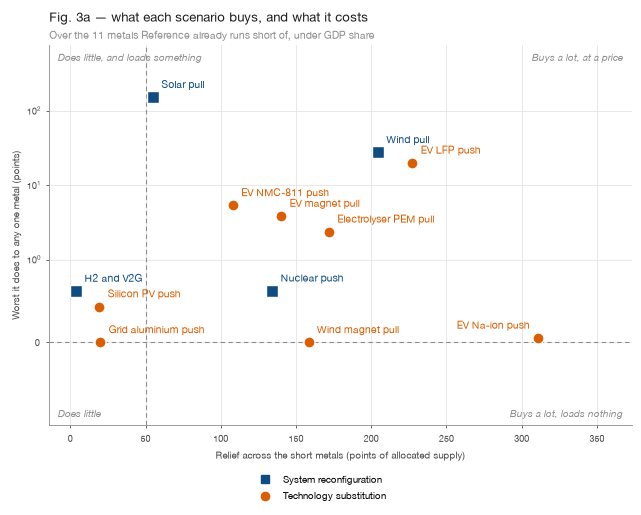

In [17]:
summary_style = scenario_effects_style["summary"]

scenario_frame = pd.DataFrame(
    {
        "x": summary_here[ScenarioSummary.relief_supply_points],
        "y": summary_here[ScenarioSummary.worst_change_supply_points],
    }
)

fig, ax = plt.subplots(
    figsize=(summary_style["panel"]["width"], summary_style["panel"]["height"]),
    layout="constrained",
)
plotting.style_scatter(
    ax,
    style,
    title="Fig. 3a — what each scenario buys, and what it costs",
    subtitle=(
        f"Over the {int(summary_here[ScenarioSummary.metals_short].iloc[0])} metals "
        f"{scenario_nice[reference]} already runs short of, under "
        f"{method_nice[reference_method]}"
    ),
    xlabel="Relief across the short metals (points of allocated supply)",
    ylabel="Worst it does to any one metal (points)",
    # The worst load spans zero to three thousand, and a scenario that loads nothing
    # sits at or below zero, which a log axis cannot hold.
    symlog_y=summary_style["linear_threshold"],
)

ax.set_xlim(-14, scenario_frame["x"].max() * 1.20)
# Just below zero, and no further: a scenario that loads nothing sits at or under
# it, and on a symmetric-log axis empty space below costs a whole decade.
ax.set_ylim(min(scenario_frame["y"].min() * 1.4, -1.0), scenario_frame["y"].max() * 5)

plotting.quadrant_split(
    ax,
    summary_style["quadrants"]["relief_supply_points"],
    0.0,
    summary_style["quadrants"],
    {
        "upper left": "Does little, and loads something",
        "upper right": "Buys a lot, at a price",
        "lower left": "Does little",
        "lower right": "Buys a lot, loads nothing",
    },
)
plotting.plain_points(
    ax,
    scenario_frame,
    kind_color,
    kind_marker,
    summary_style["point_size"],
    style["ink"],
)
plotting.label_points(
    ax, scenario_frame, scenario_nice, kind_color, summary_style["label"]
)

legend = fig.legend(
    handles=plotting.marker_handles(
        scenario_type_style,
        {kind: spec["marker"] for kind, spec in scenario_type_style.items()},
        kind_nice,
        style["ink"]["secondary"],
        colors={kind: spec["color"] for kind, spec in scenario_type_style.items()},
    ),
    frameon=False,
    # One column: the three scenario kinds carry a sentence each, and two of them
    # side by side set the figure wider than the page.
    ncol=1,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.0),
)
plotting.save_figure(
    fig, figures_dir, "scenario_relief_and_collateral", style, (legend,)
)

free = summary_here[summary_here[ScenarioSummary.metals_loaded] == 0]
print(
    "scenarios that load no short metal by more than "
    f"{scenario_effects_style['material_points']:g} point: "
    f"{', '.join(scenario_nice[s] for s in free.index) or 'none'}"
)
fixes = summary_here[summary_here[ScenarioSummary.metals_resolved] > 0]
for scenario, row in fixes.iterrows():
    print(
        f"  {scenario_nice[scenario]} alone brings "
        f"{int(row[ScenarioSummary.metals_resolved])} metal(s) back under allocated "
        f"supply, at worst {row[ScenarioSummary.worst_change_supply_points]:+.0f} "
        f"points on {row[ScenarioSummary.worst_change_metal]}"
    )

### Fig. 3b — the whole trade matrix

Fig. 3a's two numbers per scenario, unpacked into the fifteen they came from. Rows
are metals in Fig. 1b's order — worst-off first — and columns are scenarios, blocked
by the group the config puts them in, i.e. by which metals each one interrogates.
Blue is relief, red is load, and a cell's saturation is the size of the move in
percentage points of allocated supply — linearly, so two cells can be compared by
eye and one past the end of the scale saturates and carries its number.

Two patterns are visible here and nowhere else.

**The mirror.** The two MGA pulls are near-inverses of each other: what one
relieves the other loads, metal for metal. That is what a `system` scenario *is* in
this model — the energy system has to be built out of something, so pushing
capacity away from wind puts it on solar, and the metals follow. The cell below
prints the most opposed pair.

**The narrow scenarios.** Silicon PV reaches two visible cells — tellurium and
germanium — and the thin-film metals are the whole of what it touches. EV motor
induction touches the magnet rare earths and gallium and nothing else. A scenario
that only reaches a few metals is not thereby a bad scenario — but it cannot be the
answer for the metals it does not reach, and the matrix says which those are.

The row order means the top of the matrix is where relief is worth most. A dense
blue column that only starts halfway down is a scenario solving problems the study
does not have.

past the colour scale, so saturated and carrying their number:
  Electrolyser PEM pull -> Iridium: -171 points
  EV Na-ion push -> Cobalt: -198 points
  EV LFP push -> Cobalt: -198 points
  Solar pull -> Terbium: +153 points

the most opposed pair is Wind pull and Solar pull (rank correlation -0.95): what one relieves, the other loads


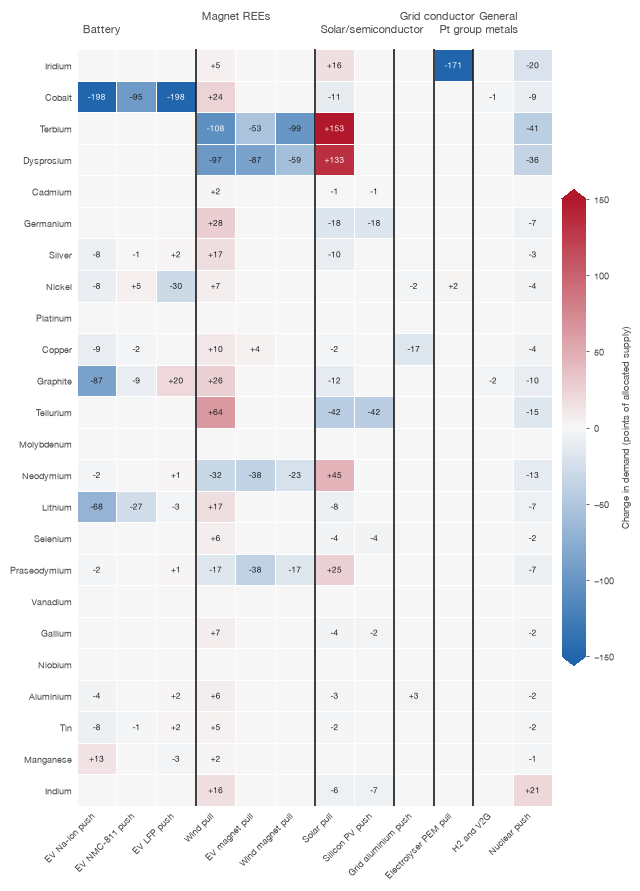

In [18]:
heatmap_style = scenario_effects_style["heatmap"]

matrix = (
    effects_here.pivot(
        index=str(ScenarioEffect.metal),
        columns=str(ScenarioEffect.scenario),
        values=str(ScenarioEffect.delta_supply_points),
    )
    # Metals in Fig. 1b's order, worst-off first; scenarios blocked by group.
    .reindex(index=floor_metals, columns=scenario_order)
    .rename(columns=scenario_nice)
)

cmap, norm = plotting.diverging_scale(heatmap_style)
fig, ax = plotting.matrix_figure(matrix, heatmap_style, style)
mesh, headers = plotting.heat_matrix(
    ax,
    matrix,
    cmap,
    norm,
    heatmap_style,
    style,
    # No title: the caption is written where the figure is published, so the
    # units and the direction of the colour are left to the colourbar.
    title=None,
    groups=group_blocks,
)

# extendfrac: the default arrow head takes a third of the bar, which reads as a
# category of its own rather than as "past the end of the scale".
colours = fig.colorbar(
    mesh, ax=ax, extend="both", extendfrac=0.02, pad=0.02, fraction=0.05
)
colours.set_label(
    "Change in demand (points of allocated supply)", color=style["ink"]["secondary"]
)
colours.outline.set_visible(False)
colours.ax.tick_params(colors=style["ink"]["secondary"])

plotting.save_figure(
    fig, figures_dir, "scenario_effects_matrix_by_metal", style, (colours.ax, *headers)
)

beyond = matrix[matrix.abs() > heatmap_style["max_points"]].stack()
print("past the colour scale, so saturated and carrying their number:")
for (metal, scenario), value in beyond.items():
    print(f"  {scenario} -> {metal}: {value:+,.0f} points")

# Two scenarios whose columns are opposites move the same metals in opposite
# directions: between them there is a trade and no net relief at all.
opposition = matrix.corr(method="spearman")
np.fill_diagonal(opposition.to_numpy(), np.nan)
first = opposition.min().idxmin()
second = opposition[first].idxmin()
print(
    f"\nthe most opposed pair is {first} and {second} (rank correlation "
    f"{opposition.loc[first, second]:.2f}): what one relieves, the other loads"
)

### Fig. 3c — the same trade, read the other way up

Fig. 3b colours the *move* and puts the metals in the rows. This turns the matrix
over: **scenarios are the rows**, so a row is one decision's whole effect read left
to right, and **colour is the state the scenario leaves the metal in** rather than
how far it moved it. The number in the cell still carries the move, so the two
readings sit in one figure.

The bands are the three allocation principles' parity levels, so a cell's hue
says which claims on world supply would still cover that metal after the scenario,
and its shade how deep into that band it sits. The ladder runs cool to warm as
the state worsens — blue, green, gold, red — so warmth alone says how bad a cell
is, and the top band, short even under the principle everything here divides by,
is the only red one: an unbroken red row is a scenario that leaves its metals short
whatever else it does, and an empty row is a scenario that does nothing.

The strip over the columns is what the scenarios are acting on: the span every
scenario leaves the metal in, the reference inside it, and the other-sector floor
no scenario reaches past — the wall the span's lower end can never pass, which is
what separates a metal the scenarios merely fail to fix (dysprosium, with 85 points
of headroom unused) from one they could never have fixed (platinum, whose floor
alone is three and a half times allocated supply). It shares the colour bar's
axis, so the strip and the cells are the same scale and the same thresholds.

The metal names over the columns carry their supply-side character, in the same
two classes and the same way Fig. 1c writes them: a metal whose output is a
fraction of another's is a different kind of problem from one whose is not, and
no cell of the matrix says so.

This is the version the published notebook draws.

scenarios that move nothing by 1 points or more, so draw an empty row: none
short at Reference: 11 of 24 metals; a scenario takes Copper, Graphite under parity, while Iridium, Cadmium, Germanium, Silver, Platinum are past it on other-sector demand alone


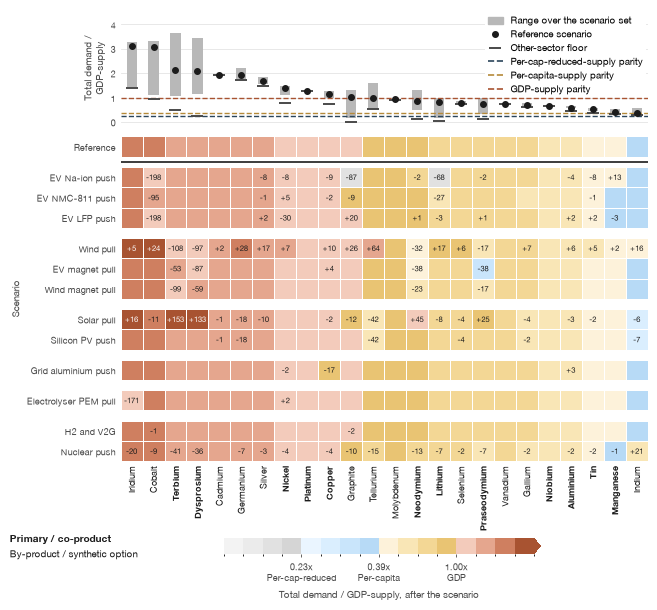

In [19]:
matrix_style = scenario_effects_style["matrix"]

# The reference is a row of its own above the scenarios, ruled off from them: it is
# not a decision but the state every other row is measured from. The scenarios keep
# Fig. 3b's group blocks, set apart here by blank space rather than ruled off
# and named — a scenario is read against every metal, not against the ones its
# own group is named for.
row_order = [reference, *scenario_order]
row_blocks = [0, *(1 + start for start in group_blocks)]

# `methods` is strictest first, so the parities ascend with it. A parity is its
# principle's supply line, so it is drawn in that line's style on every figure.
parity_style = {
    m: {
        "color": allocation_style[m]["supply_color"],
        "linestyle": allocation_style[m]["supply_linestyle"],
    }
    for m in methods
}
parity_lines = {ratio_parity[m]: parity_style[m] for m in methods}
parity_key = {f"{method_short[m]}-supply parity": parity_style[m] for m in methods}


def scenario_frame(column, metals):
    """One value per (scenario, metal), in the figure's row order and `metals`.

    The column order is the caller's because the two figures below disagree on
    it: each puts its own most-demanded metal first, and dropping other-sector
    demand reorders them almost completely.
    """
    return effects_here.pivot(
        index=str(ScenarioEffect.scenario),
        columns=str(ScenarioEffect.metal),
        values=str(column),
    ).reindex(index=row_order, columns=metals)


def scenario_matrix(
    cells, moves, strip, colour_label, name, colour="state", parities=True
):
    """The scenario x metal matrix over its strip, written out as `name`.

    Every figure below is this one design, and the frames handed in carry what
    separates them — as one `position_panel` draws Fig. 2 and its end-use twin in
    the published notebook. Three things are parameters because they differ in
    more than a frame: a strip with no `floor` column draws none, which is what
    the reading without other-sector demand wants; `colour` says what the cells
    are measured on; and `parities` says whether the allocation principles'
    levels are thresholds this reading can cross at all.

    "state" bands the cells by where the scenario leaves the metal, against those
    parities; "change" puts the move itself on the diverging scale Fig. 3b uses,
    so relief and load are the two directions from a middle that means "this
    scenario does nothing here"; "spectrum" grades them on one ramp in even steps,
    for a quantity that is a level rather than a distance from a threshold. `cells`
    is whichever of the three the colour is on; `moves` is always the number.

    `parities` false drops the dashed levels from the strip and their entries
    from the key: a demand that is not the whole demand charged to the region is
    neither over nor under the region's claim, so the line would invite a
    crossing to be read where there is none.
    """
    if strip["high"].max() > matrix_style["cap"]:
        raise ValueError(
            f"compare.scenario_effects.matrix.cap is {matrix_style['cap']}, below the worst "
            f"scenario's demand for {strip['high'].idxmax()} "
            f"({strip['high'].max():.2f}x), whose bar the strip would clip"
        )

    if colour == "state":
        cmap, norm = plotting.band_scale(
            [ratio_parity[m] for m in methods], matrix_style
        )
    elif colour == "change":
        cmap, norm = plotting.diverging_scale(heatmap_style)
    elif colour == "spectrum":
        cmap, norm = plotting.spectrum_scale(matrix_style)
    else:
        raise ValueError(
            f"colour is {colour!r}; expected 'state', 'change' or 'spectrum'"
        )

    fig, (strip_axes, ax) = plotting.matrix_strip_figure(
        cells, matrix_style, row_blocks=row_blocks
    )
    mesh, headers = plotting.heat_matrix(
        ax,
        cells.rename(index=scenario_nice),
        cmap,
        norm,
        matrix_style,
        style,
        title=None,
        row_rules=[1],
        row_blocks=row_blocks,
        numbers=moves,
        column_label_styles=metal_label_style,
        ylabel=matrix_style["ylabel"],
    )
    quantity = "Total demand" if "floor" in strip else "Energy system demand"
    plotting.level_strip(
        strip_axes, strip, parity_lines if parities else {}, matrix_style, style,
        ylabel=f"{quantity} /\n{method_short[reference_method]}-supply",
    )
    # The strip's marks are named in the strip, the column names under the matrix.
    plotting.strip_key(
        strip_axes,
        matrix_style,
        style,
        reference=f"{scenario_nice[reference]} scenario",
        parities=parity_key if parities else {},
        floor="Other-sector floor" if "floor" in strip else None,
    )

    # Horizontal either way: the matrix is sized to a portrait page, so the bar
    # cannot have the width it would take standing beside the panel.
    if colour == "state":
        colours = plotting.band_colorbar(
            fig, mesh, [strip_axes, ax],
            {method_short[m]: ratio_parity[m] for m in methods},
            style,
            label=colour_label,
            orientation="horizontal",
        )
    else:
        if colour == "spectrum":
            # No arrow: the check above puts `cap` past the worst cell. Its steps
            # are even and mean nothing, so whole numbers tick it, not their edges.
            ends = {"ticks": np.arange(np.floor(matrix_style["cap"]) + 1)}
        else:
            # extendfrac: the default arrow head takes a third of the bar, which
            # reads as a category of its own rather than as "past the end".
            ends = {"extend": "both", "extendfrac": 0.02}
        colours = fig.colorbar(
            mesh, ax=[strip_axes, ax], orientation="horizontal",
            pad=0.015, fraction=0.035, **ends,
        )
        colours.set_label(colour_label, color=style["ink"]["secondary"])
        colours.outline.set_visible(False)
        colours.ax.tick_params(colors=style["ink"]["secondary"], length=2)
    # In the corner under the row names, level with the colour bar.
    legend = plotting.corner_key(
        fig, colours.ax, {label: class_label_style[name] for label, name in class_key.items()}
    )
    outside = (colours.ax, legend, *headers)
    plotting.save_figure(fig, figures_dir, name, style, outside)
    # Returned so a caller can write the same drawing out under a second name —
    # `save_figure` needs the artists that sit outside the axes, and only this
    # function has them.
    return fig, outside


total_colour_label = (
    f"Total demand / {method_short[reference_method]}-supply, after the scenario"
)


def total_frames(metals_order):
    """This figure's three frames — state, moves, strip — in a column order.

    Colour is where a scenario leaves the metal; the number printed on it is how far
    it moved it, which the reference row — being the origin — has none of. The
    moves serve Figs. 3di and 3dii unchanged as well: other-sector demand is a
    constant per metal, so it cancels out of every delta and only the state it
    is added to moves. The order is the caller's because Figs. 3e and 3f draw this same
    figure sorted two other ways.
    """
    state = scenario_frame(ScenarioEffect.total_over_supply, metals_order)
    state.loc[reference] = placed[MetalPosition.total_over_supply_base].reindex(
        metals_order
    )
    strip = pd.DataFrame(
        {
            "low": placed[MetalPosition.total_over_supply_reduced],
            "high": placed[MetalPosition.total_over_supply_raised],
            "reference": placed[MetalPosition.total_over_supply_base],
            "floor": placed[MetalPosition.non_energy_over_supply],
        }
    ).reindex(metals_order)
    moves = scenario_frame(ScenarioEffect.delta_supply_points, metals_order)
    return state, moves, strip


state, moves, strip = total_frames(floor_metals)
# Under its own file name, not the published Fig. 3's: that figure is written
# by a rule, and a manual run of this notebook must not overwrite it.
scenario_matrix(state, moves, strip, total_colour_label, "scenario_effects_matrix_rough")

material = moves.abs() >= matrix_style["annotate_above"]
idle = [s for s in scenario_order if not material.loc[s].any()]
print(f"scenarios that move nothing by {matrix_style['annotate_above']:.0f} points or "
      f"more, so draw an empty row: {', '.join(scenario_nice[s] for s in idle) or 'none'}")

short = strip[strip["reference"] > ratio_parity[reference_method]]
reachable = short[short["low"] <= ratio_parity[reference_method]]
locked = short[short["floor"] > ratio_parity[reference_method]]
print(f"short at {scenario_nice[reference]}: {len(short)} of {len(strip)} metals; "
      f"a scenario takes {', '.join(reachable.index) or 'none'} under parity, while "
      f"{', '.join(locked.index)} are past it on other-sector demand alone")


### Fig. 3di — Fig. 3c with other-sector demand taken out

The first of the two steps between Fig. 3c and Fig. 3dii, and the one that
changes the quantity: the same rows, the same bands, the same parity lines and
the same moves printed on the cells, with the state measured over the energy
system's demand alone.

The numbers are identical to Fig. 3c's. Other-sector demand is a constant per
metal, so it cancels out of every delta; only the state those moves are added to
changes, and it changes a long way. Most of the short metals are short because
of what the other sectors already take, not because of anything the energy
system builds, and that is the whole of what this figure says.

**The columns are sorted on this reading**, worst-off first, which is a very
different order from Fig. 3c's: platinum, germanium and cadmium head that figure
on other-sector demand and fall to the back here, while cobalt and the magnet
REEs come to the front. Fig. 3f is Fig. 3c drawn in this order, so the two stack
and can be read column by column — the same metal in the same place, once with
the other sectors counted and once without.

The strip keeps its span, its reference and its dashed parity levels, and loses
only its floor tick — the floor being the thing left out. The bands are kept
here deliberately, so the panel can be read against Fig. 3c's with one encoding
still in common. They claim more than this quantity supports, which is what
Fig. 3dii removes.

short at Reference: 11 of 24 metals counting every sector, 5 counting the energy system alone
  short either way: Iridium, Cobalt, Terbium, Dysprosium, Graphite
  short only once other sectors are counted: Cadmium, Germanium, Silver, Nickel, Platinum, Copper
  columns in this figure's order: Cobalt, Dysprosium, Iridium, Terbium, Graphite, Lithium, Neodymium, Nickel, Praseodymium, Tellurium, Copper, Silver, Germanium, Tin, Aluminium, Gallium, Manganese, Indium, Selenium, Platinum, Molybdenum, Cadmium, Vanadium, Niobium


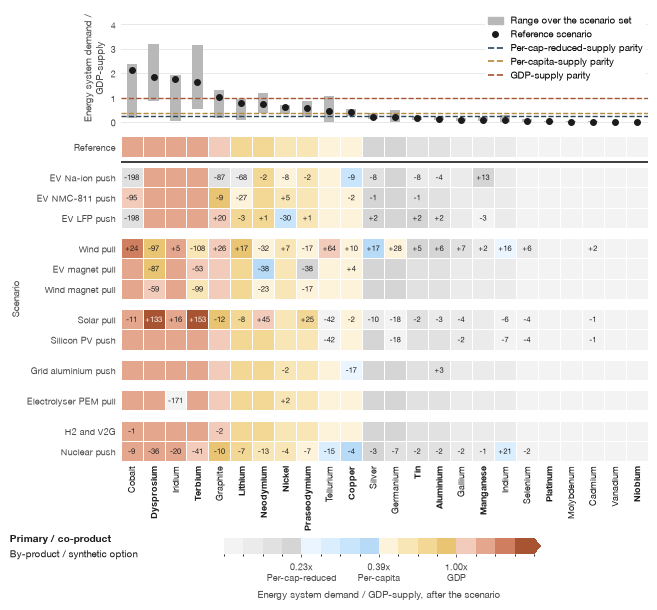

In [20]:
def energy_frames(metals_order):
    """`total_frames`'s three frames, over the energy system's demand alone.

    The moves are the same frame in both readings: other-sector demand is a
    constant per metal, so it cancels out of every delta. The strip has no
    `floor` column — the floor is the quantity being left out — and
    `scenario_matrix` draws it without one.
    """
    state = scenario_frame(ScenarioEffect.energy_over_supply, metals_order)
    state.loc[reference] = placed[MetalPosition.energy_over_supply_base].reindex(
        metals_order
    )
    strip = pd.DataFrame(
        {
            "low": placed[MetalPosition.energy_over_supply_reduced],
            "high": placed[MetalPosition.energy_over_supply_raised],
            "reference": placed[MetalPosition.energy_over_supply_base],
        }
    ).reindex(metals_order)
    moves = scenario_frame(ScenarioEffect.delta_supply_points, metals_order)
    return state, moves, strip


energy_colour_label = (
    f"Energy system demand / {method_short[reference_method]}-supply, after the scenario"
)

# Worst-off first on this figure's own reading, which Fig. 3dii and Fig. 3f
# share so that all three can be laid one over another column by column.
energy_order = list(
    placed[MetalPosition.energy_over_supply_base]
    .reindex(floor_metals)
    .sort_values(ascending=False)
    .index
)
energy_state, energy_moves, energy_strip = energy_frames(energy_order)

scenario_matrix(
    energy_state,
    energy_moves,
    energy_strip,
    energy_colour_label,
    "scenario_effects_matrix_no_ned_banded",
)

parity = ratio_parity[reference_method]
short_total = [m for m in floor_metals if strip.loc[m, "reference"] > parity]
short_energy = [m for m in energy_order if energy_strip.loc[m, "reference"] > parity]
print(f"short at {scenario_nice[reference]}: {len(short_total)} of {len(strip)} metals "
      f"counting every sector, {len(short_energy)} counting the energy system alone")
print("  short either way: " + ", ".join(m for m in short_total if m in short_energy))
print("  short only once other sectors are counted: "
      + ", ".join(m for m in short_total if m not in short_energy))
print("  columns in this figure's order: " + ", ".join(energy_order))

### Fig. 3dii — the same again, without the allocation thresholds

Fig. 3di keeps Fig. 3c's bands, which is what lets the two be read against each
other — but the reading those bands carry does not survive the removal. A cell
here is not the whole demand charged to the region, so it is neither over nor
under the region's claim: a hue saying *which principles would still cover this
metal* claims something the quantity cannot support, and the dashed levels in
the strip invite a crossing to be read where there is none.

So this is Fig. 3di with that claim dropped, and the last figure of the set. One
ramp over the same 0-to-`cap` range as Fig. 3c, cut into as many steps as Fig.
3c's bands have shades but evenly — darker is more, and no boundary in it means
anything — and a strip carrying the span and the reference alone.

Taken together, Figs. 3di and 3dii set the energy system's demand alone against
allocated supply where Fig. 3c sets every sector's. That is a sensitivity on the
accounting and not a second result: leaving other-sector demand out asks a more
generous question, since it hands the transition the region's *whole* claim on
world supply and gives the other sectors none of it.

It is written out under the names it is referred to by outside this notebook as
well — what it leaves out is other-sector demand, which is what "energy only"
means and what "no NED" says.

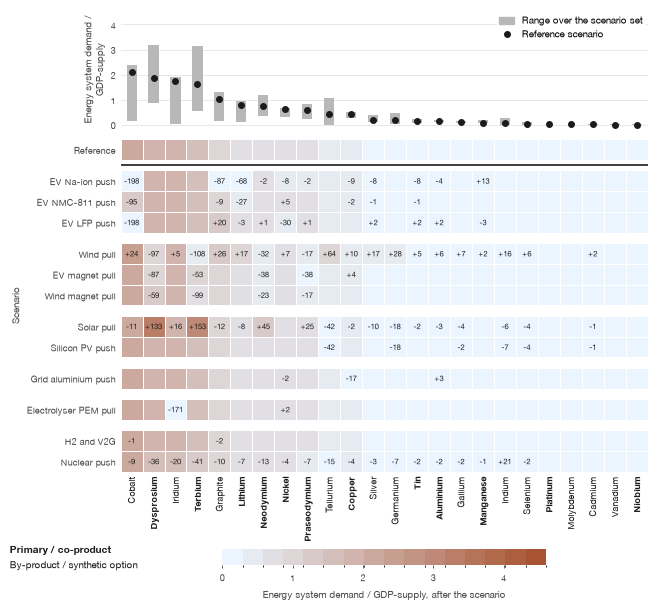

In [21]:
fig, outside = scenario_matrix(
    energy_state,
    energy_moves,
    energy_strip,
    energy_colour_label,
    "scenario_effects_matrix_no_ned_unbanded",
    colour="spectrum",
    parities=False,
)
# The same drawing under the two names it is referred to by outside this
# notebook. `save_figure` needs the artists sitting outside the axes, which is
# why `scenario_matrix` hands them back.
for name in ("scenario_effects_matrix_energy_only", "scenario_effects_matrix_no_ned"):
    plotting.save_figure(fig, figures_dir, name, style, outside)

### Figs. 3e and 3f — Fig. 3c under two other column orders

The same figure as Fig. 3c in every other respect — every sector's demand as the
state, the same moves printed on the cells, the same colour scale — sorted two
other ways, so what the sort is doing to the reading can be seen rather than
assumed.

**Fig. 3e** takes Fig. 1's order: `mineral_info.csv`'s, i.e. the metals blocked
by what they are wanted for. It is the order that makes a scenario's effect legible
as a *technology* story — the magnet REEs together, the battery metals together —
at the cost of scattering the short metals across the panel.

**Fig. 3f** takes Fig. 3di's order, worst-off first on energy-system demand alone,
so that figure and this one can be laid one above the other and read column by
column: the same metal in the same place, once with the other sectors counted and
once without.


Fig. 3e, Fig. 1's end-use order: Aluminium, Copper, Cadmium, Gallium, Germanium, Indium, Selenium, Tellurium, Cobalt, Graphite, Lithium, Dysprosium, Neodymium, Praseodymium, Terbium, Iridium, Platinum, Manganese, Molybdenum, Nickel, Niobium, Silver, Tin, Vanadium
Fig. 3f, Fig. 3di's order: Cobalt, Dysprosium, Iridium, Terbium, Graphite, Lithium, Neodymium, Nickel, Praseodymium, Tellurium, Copper, Silver, Germanium, Tin, Aluminium, Gallium, Manganese, Indium, Selenium, Platinum, Molybdenum, Cadmium, Vanadium, Niobium


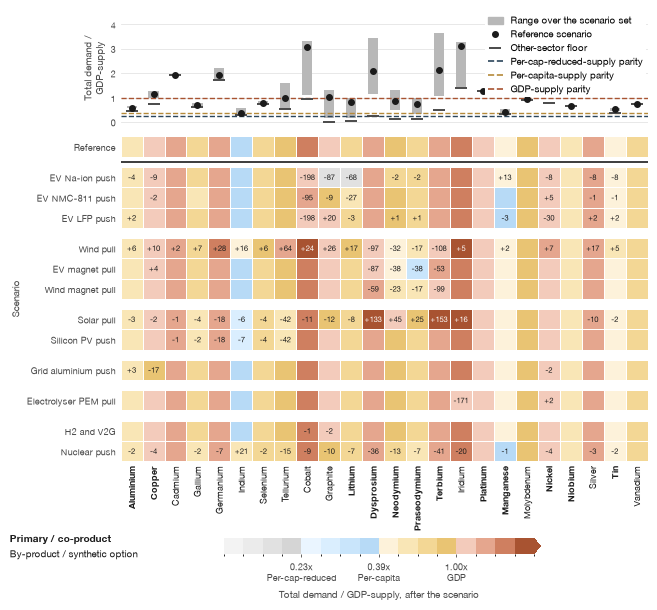

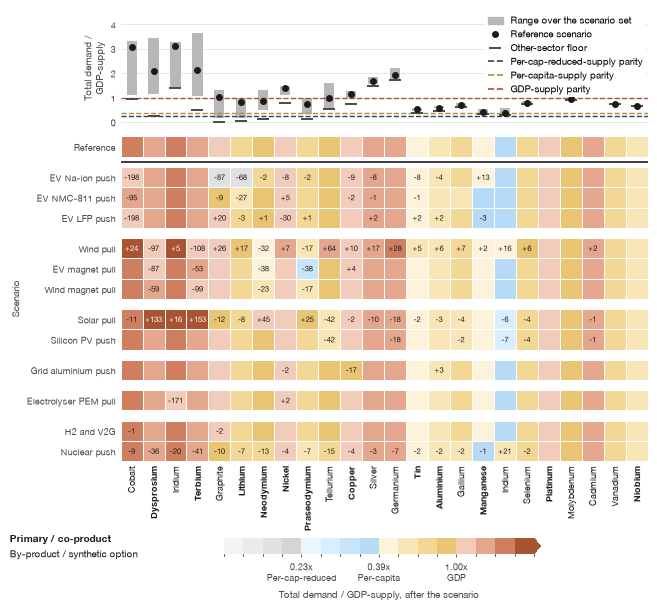

In [22]:
# Fig. 1 draws its bars from `grouped`, block by block, so its order is that
# dict flattened and not `metals` — which is the order mineral_info.csv happens
# to list them in, alphabetical, and no figure's.
end_use_order = [metal for block in grouped.values() for metal in block]

# Nothing changes but the column order, so the frames are rebuilt in it and
# handed to the same drawing function.
for metals_order, name in [
    (end_use_order, "scenario_effects_matrix_by_end_use"),
    (energy_order, "scenario_effects_matrix_energy_order"),
]:
    scenario_matrix(*total_frames(metals_order), total_colour_label, name)

print("Fig. 3e, Fig. 1's end-use order: " + ", ".join(end_use_order))
print("Fig. 3f, Fig. 3di's order: " + ", ".join(energy_order))


### Fig. 3g — Fig. 3c coloured by the move instead of the destination

The same figure again — the same rows, the same columns in Fig. 3c's order, the
same strip saying what each scenario is acting on — with the cells coloured by
**what the scenario does** rather than by where it leaves the metal. Relief and load
are the two directions from a middle that means the scenario does nothing here, on
the diverging scale Fig. 3b uses, so the two figures are read with one palette.

It is Fig. 3b's quantity in Fig. 3c's layout, and it answers the other half of
the question: Fig. 3c says which cells matter, this says which cells move. A
scenario can be strong here and useless there — a big move on a metal already deep
in the warm band leaves it deep in the warm band — which is exactly what reading
the two side by side is for.

The reference row is blank by construction: it is the origin every move is
measured from, so its own change is zero.


past the colour scale, so saturated and carrying their number:
  EV Na-ion push -> Cobalt: -198 points
  EV LFP push -> Cobalt: -198 points
  Solar pull -> Terbium: +153 points
  Electrolyser PEM pull -> Iridium: -171 points


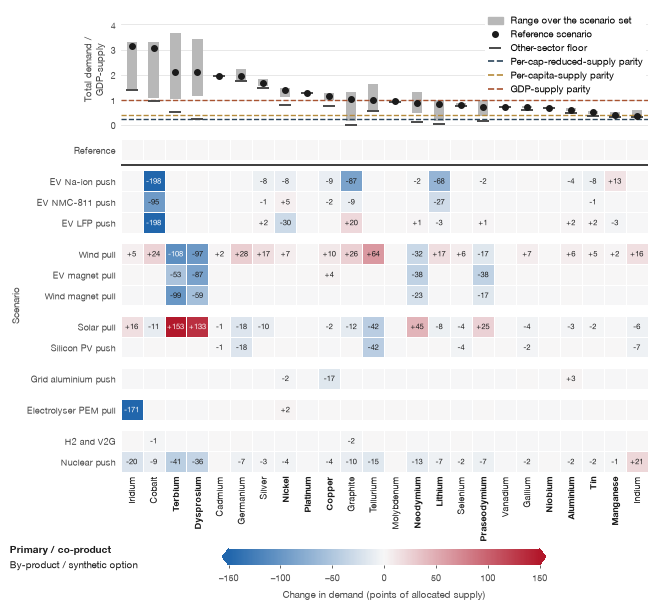

In [23]:
# The cells are the moves themselves; the reference row is the origin they are
# measured from, so it is zero rather than missing.
change_cells = moves.copy()
change_cells.loc[reference] = 0.0

scenario_matrix(
    change_cells,
    moves,
    strip,
    "Change in demand (points of allocated supply)",
    "scenario_effects_matrix_change",
    colour="change",
)

beyond = moves[moves.abs() > heatmap_style["max_points"]].stack()
print("past the colour scale, so saturated and carrying their number:")
for scenario, metal in beyond.index:
    print(f"  {scenario_nice[scenario]} -> {metal}: {beyond[scenario, metal]:+,.0f} points")


## Archive below

In [24]:
methods

['per_capita_energy_corrected', 'per_capita', 'gdp']

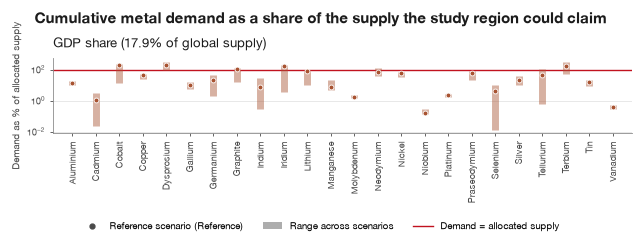

In [25]:
PARITY_COLOR = "#c1121f"  # the 100% line: demand exactly equal to allocated supply


def share_panel(ax, method):
    """Demand as a percentage of `method`'s ceiling, one entry per metal.

    The scenario spread is drawn as a band from the lowest to the highest scenario
    and the reference scenario as a marker on top, so a metal reads as a level and
    a sensitivity at once.
    """
    ratio = share_of_supply.sel(allocation_method=method, metal=metals)
    low = ratio.min("scenario").to_numpy()
    high = ratio.max("scenario").to_numpy()
    ref = ratio.sel(scenario=reference).to_numpy()
    x = np.arange(len(metals))
    color = allocation_style[method]["supply_color"]

    ax.vlines(x, low, high, color=color, alpha=0.45, linewidth=5, zorder=2)
    ax.plot(x, ref, "o", color=color, markersize=3.5,
            markeredgecolor=style["ink"]["surface"], markeredgewidth=0.6, zorder=3)
    ax.axhline(100, color=PARITY_COLOR, linewidth=1.0, zorder=1)

    share = float(supply["study_share"].sel(allocation_method=method))
    plotting.style_panel(
        ax,
        style,
        title=f"{method_nice[method]} ({share:.1%} of global supply)",
        ylabel="Demand as % of allocated supply",
        log=True,
    )
    plotting.category_axis(
        ax,
        {metal: float(index) for index, metal in enumerate(metals)},
        {metal: metal for metal in metals},
        style,
        panel_key="metal_axis",
    )


# One panel per allocation principle, on a shared y-axis: the principles differ
# by a constant factor, so the shared axis shows the ceiling tightening.
SHARE_METHODS = ["gdp"]
fig, axes = plotting.page_grid(
    len(SHARE_METHODS), style, max_columns=1,
    row_height=style["supplement"]["wide_row"], sharey=True,
)
for ax, method in zip(axes, SHARE_METHODS):
    share_panel(ax, method)

key = fig.legend(
    handles=[
        mlines.Line2D([], [], color=style["ink"]["secondary"], marker="o",
                      linestyle="none", markersize=3.5,
                      label=f"Reference scenario ({scenario_nice[reference]})"),
        mpatches.Patch(facecolor=style["ink"]["secondary"], alpha=0.45,
                       label="Range across scenarios"),
        mlines.Line2D([], [], color=PARITY_COLOR, linewidth=1.0,
                      label="Demand = allocated supply"),
    ],
    frameon=False, ncol=3, loc="outside lower center",
)
suptitle = fig.suptitle(
    "Cumulative metal demand as a share of the supply the study region could claim",
    color=style["ink"]["primary"],
)
plotting.save_figure(
    fig, figures_dir, "demand_share_of_supply", style, (key, suptitle)
)
